### Inspecting the Dataset Directory
First, let's explore the directory structure of the downloaded competition files to locate the image and mask files.

In [ ]:
import os
import json
import kagglehub

# Configure Kaggle credentials using the uploaded kaggle.json file
with open('/content/kaggle.json', 'r') as f:
    kaggle_config = json.load(f)

os.environ['KAGGLE_USERNAME'] = kaggle_config['username']
os.environ['KAGGLE_KEY'] = kaggle_config['key']

try:
    print(f"Attempting download using username: {os.environ['KAGGLE_USERNAME']}")
    path = kagglehub.competition_download('filament-segmentation-2026')
    print("Successfully downloaded! Path to competition files:", path)
except Exception as e:
    print(f"Failed to download. Error: {e}")

Attempting download using username: baldwinjames827


100%|██████████| 671M/671M [00:17<00:00, 40.7MB/s]

Extracting files...


Successfully downloaded! Path to competition files: /root/.cache/kagglehub/competitions/filament-segmentation-2026


In [ ]:
import os

dataset_path = '/root/.cache/kagglehub/competitions/filament-segmentation-2026'
for root, dirs, files in os.walk(dataset_path):
    # Only print top-level structure to avoid flooding the notebook
    depth = root.replace(dataset_path, '').count(os.sep)
    if depth < 2:
        print(f"{'-' * depth * 2}[{os.path.basename(root) or 'root'}] - contains {len(dirs)} folders, {len(files)} files")

[filament-segmentation-2026] - contains 1 folders, 0 files
--[MAGFiLO_1.0_Kaggle_2026] - contains 2 folders, 0 files


### Load, Inspect, and Display Solar Images and Masks
Now let's load a few samples, display them side-by-side, check their shapes and pixel ranges, and observe how the filament masks represent instances.

Found 887 potential images and 0 potential masks.
Searching for mask directory or paired structures...


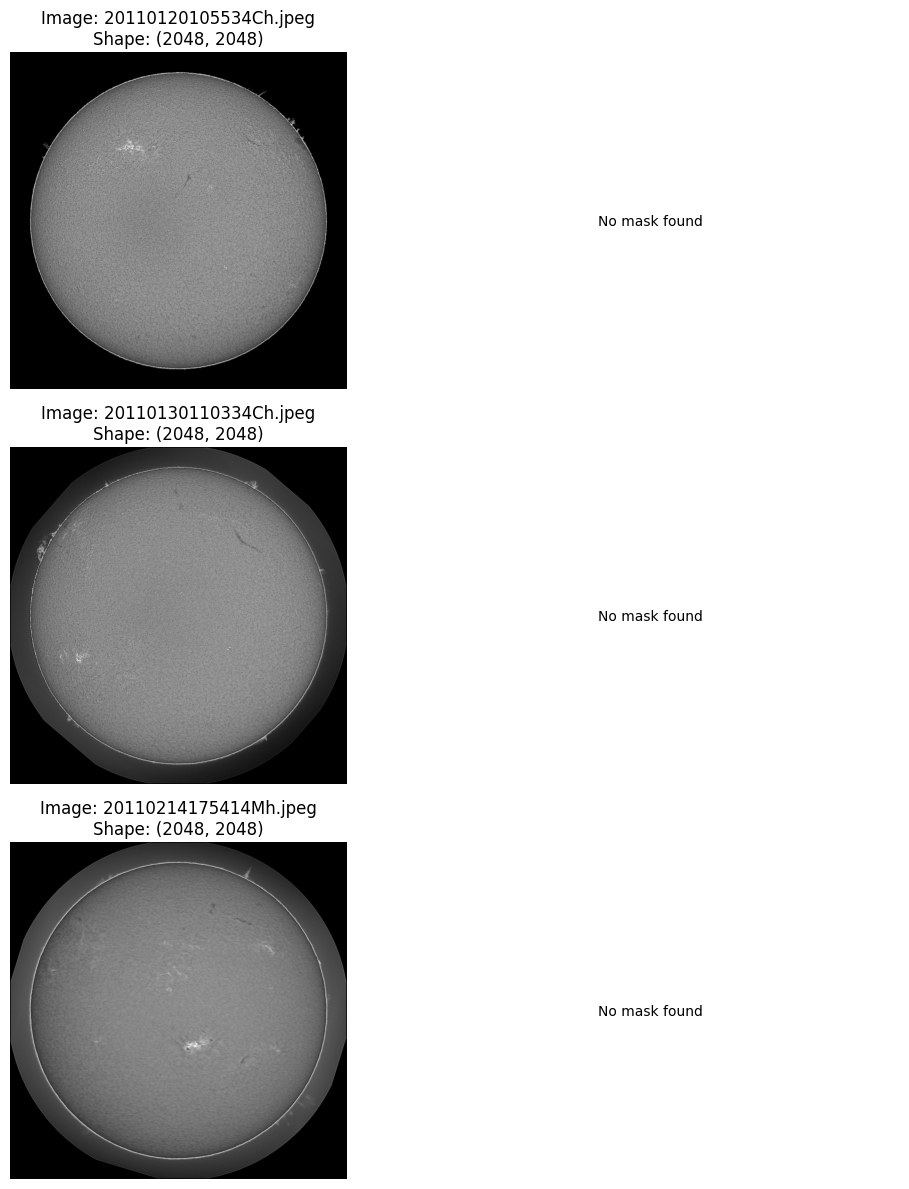

In [ ]:
import glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Look for images and masks (supporting common extensions like .jpg, .png, .fits)
all_files = glob.glob(os.path.join(dataset_path, '**/*'), recursive=True)
image_files = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.fits')) and 'mask' not in f.lower() and os.path.isfile(f)])
mask_files = sorted([f for f in all_files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.fits')) and 'mask' in f.lower() and os.path.isfile(f)])

print(f"Found {len(image_files)} potential images and {len(mask_files)} potential masks.")

# Fallback search if 'mask' is not in the filename
if len(mask_files) == 0 and len(image_files) > 0:
    print("Searching for mask directory or paired structures...")

# Let's visualize the first 3 samples side-by-side
num_samples = min(3, len(image_files))
if num_samples > 0:
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_samples):
        img_path = image_files[i]
        # Find a matching mask if possible, otherwise pick the corresponding index
        mask_path = mask_files[i] if i < len(mask_files) else None

        img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
        # Convert BGR to RGB if color image
        if img is not None and len(img.shape) == 3:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i, 0].imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        axes[i, 0].set_title(f"Image: {os.path.basename(img_path)}\nShape: {img.shape if img is not None else 'None'}")
        axes[i, 0].axis('off')

        if mask_path:
            mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
            axes[i, 1].imshow(mask, cmap='jet')
            unique_vals = np.unique(mask) if mask is not None else []
            axes[i, 1].set_title(f"Mask: {os.path.basename(mask_path)}\nShape: {mask.shape if mask is not None else 'None'}\nUnique values: {list(unique_vals)[:10]}")
        else:
            axes[i, 1].text(0.5, 0.5, 'No mask found', ha='center', va='center')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No matching images found to display. Please verify the dataset files manually.")

Found annotation file: /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
loading annotations into memory...
Done (t=0.46s)
creating index...
index created!
Total images in annotations: 1154
Image: 20140609195854Bh.jpeg | Shape: (2048, 2048, 3) | Detected Instances: 12 (IDs: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)])
Image: 20111116063134Lh.jpeg | Shape: (2048, 2048, 3) | Detected Instances: 11 (IDs: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11)])
Image: 20111116063134Lh.jpeg | Shape: (2048, 2048, 3) | Detected Instances: 11 (IDs: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11)])


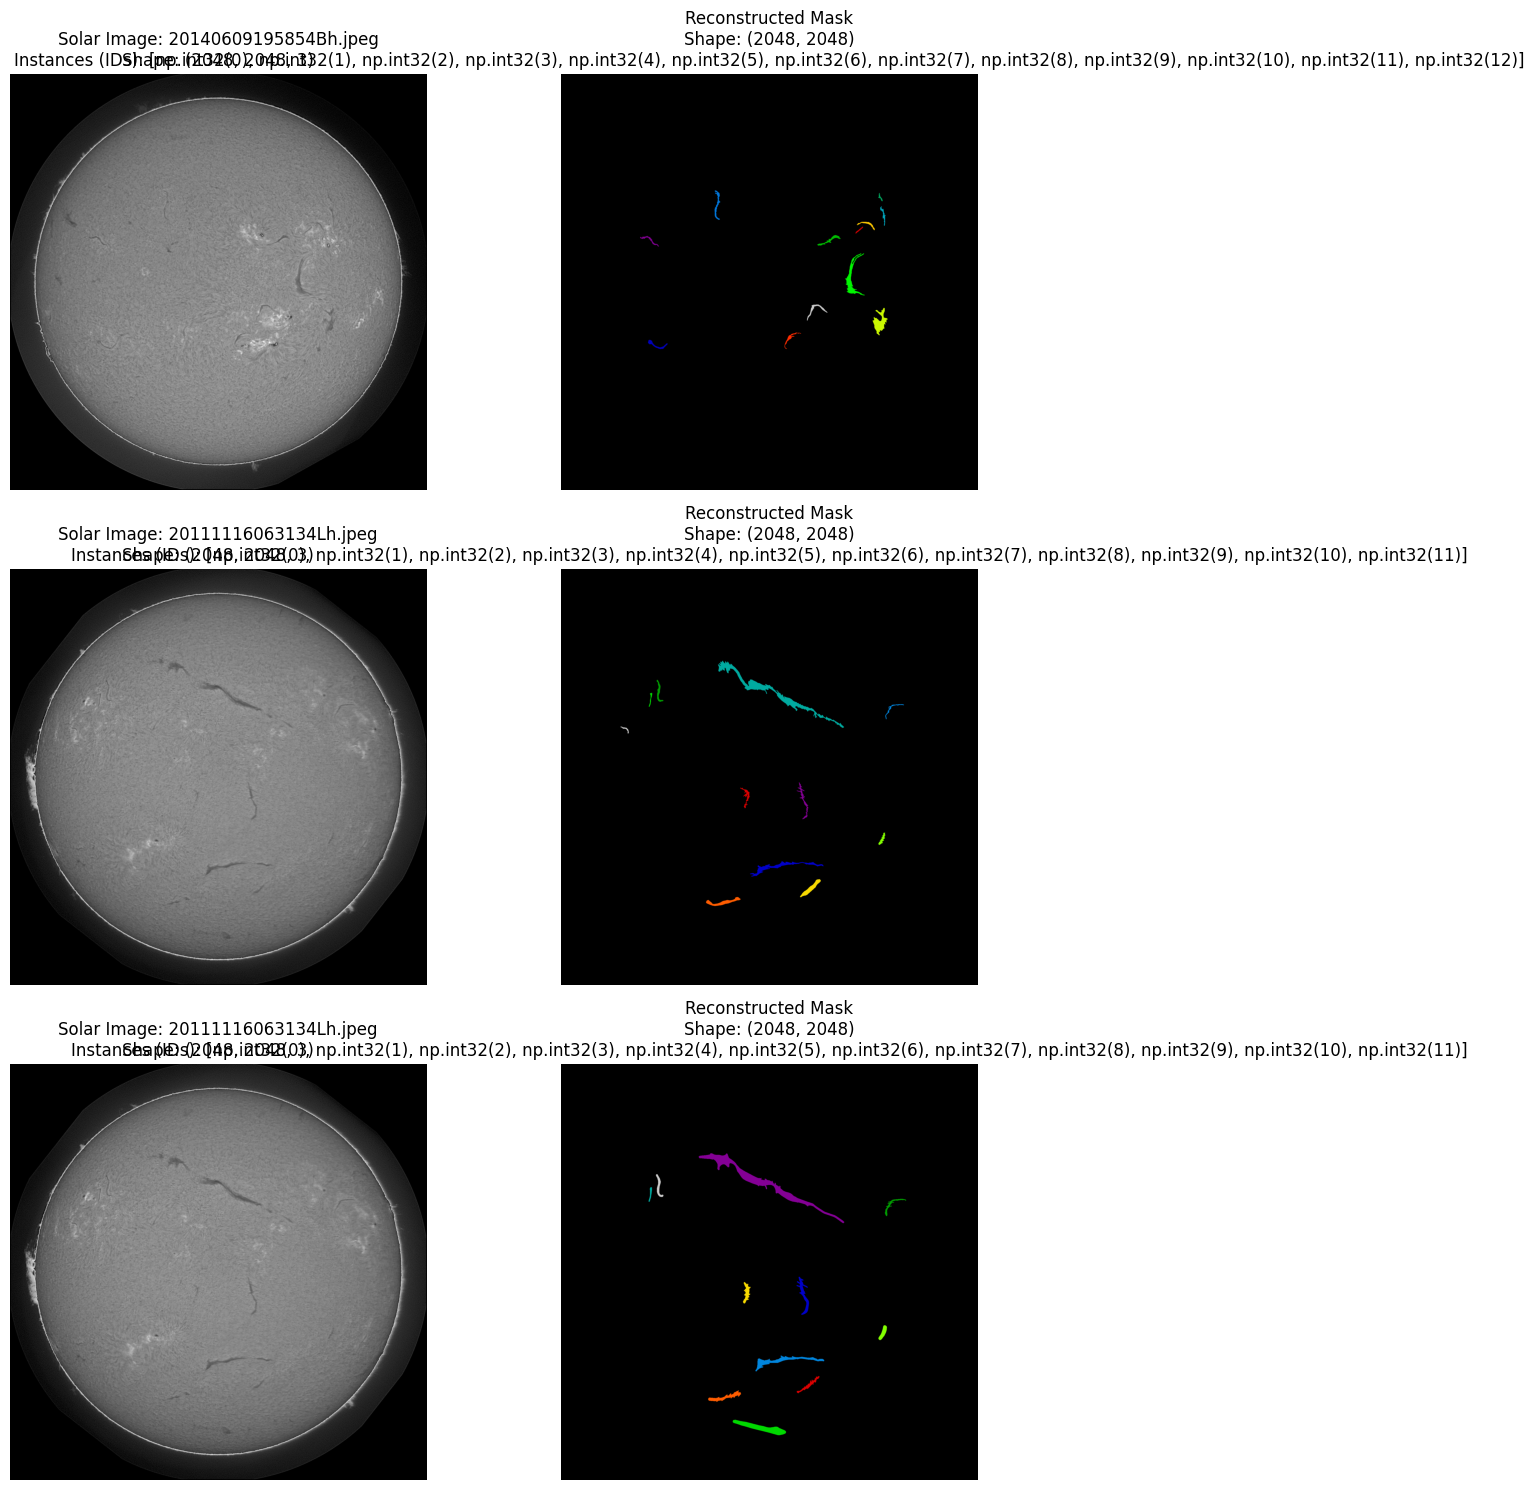

In [ ]:
import os
import json
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pycocotools.coco import COCO

# Locate the annotation file
annotation_candidates = glob.glob(os.path.join(dataset_path, '**/*.json'), recursive=True)
if not annotation_candidates:
    print("Could not find any JSON annotation files.")
else:
    ann_path = annotation_candidates[0]
    print(f"Found annotation file: {ann_path}")

    # Load COCO annotations
    coco = COCO(ann_path)

    # Get all image IDs
    img_ids = list(coco.imgs.keys())
    print(f"Total images in annotations: {len(img_ids)}")

    # Pick up to 3 images to display
    sample_img_ids = img_ids[:3]

    fig, axes = plt.subplots(len(sample_img_ids), 2, figsize=(12, 5 * len(sample_img_ids)))
    if len(sample_img_ids) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, img_id in enumerate(sample_img_ids):
        # Safely access image metadata directly from coco.imgs
        img_info = coco.imgs[img_id]
        file_name = img_info['file_name']

        # Find the image file path in dataset directories
        img_path_candidates = glob.glob(os.path.join(dataset_path, f"**/{file_name}"), recursive=True)
        if not img_path_candidates:
            print(f"Could not find image file: {file_name}")
            continue

        img_path = img_path_candidates[0]
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Initialize an empty mask of the same dimensions
        height, width = img_info['height'], img_info['width']
        # We will use integer values > 0 for different instance IDs
        instance_mask = np.zeros((height, width), dtype=np.int32)

        # Load and draw annotations
        ann_ids = coco.getAnnIds(imgIds=[img_id])
        anns = coco.loadAnns(ann_ids)

        for inst_idx, ann in enumerate(anns, start=1):
            # Draw each instance with a unique ID
            coco_mask = coco.annToMask(ann)
            instance_mask[coco_mask > 0] = inst_idx

        # Plotting
        axes[idx, 0].imshow(img)
        axes[idx, 0].set_title(f"Solar Image: {file_name}\nShape: {img.shape}")
        axes[idx, 0].axis('off')

        # Display the reconstructed instance mask using a colormap
        axes[idx, 1].imshow(instance_mask, cmap='nipy_spectral')
        unique_instances = np.unique(instance_mask)
        axes[idx, 1].set_title(f"Reconstructed Mask\nShape: {instance_mask.shape}\nInstances (IDs): {list(unique_instances)}")
        axes[idx, 1].axis('off')

        print(f"Image: {file_name} | Shape: {img.shape} | Detected Instances: {len(anns)} (IDs: {list(unique_instances[1:])})")

    plt.tight_layout()
    plt.show()

In [ ]:

from collections import Counter
import os
import numpy as np
import cv2

img_ids = list(coco.imgs.keys())

# 1. Check unique image filenames
filenames = [coco.imgs[i]["file_name"] for i in img_ids]
filename_counts = Counter(filenames)

print("Images in COCO annotations:", len(img_ids))
print("Unique filenames:", len(set(filenames)))
print("Duplicate filename entries:",
      {k: v for k, v in filename_counts.items() if v > 1})

# 2. Check dimensions and annotation counts
dimensions = Counter(
    (coco.imgs[i]["height"], coco.imgs[i]["width"])
    for i in img_ids
)
print("\nImage dimensions:", dimensions)

ann_counts = [
    len(coco.getAnnIds(imgIds=[i]))
    for i in img_ids
]
print("Images with zero annotations:",
      sum(n == 0 for n in ann_counts))
print("Min/median/max instances:",
      min(ann_counts), np.median(ann_counts), max(ann_counts))

# 3. Inspect annotation areas and bounding boxes
bad_annotations = []
for ann_id, ann in coco.anns.items():
    if ann.get("area", 0) <= 0:
        bad_annotations.append(ann_id)

print("Annotations with non-positive area:", len(bad_annotations))


Images in COCO annotations: 1154
Unique filenames: 707
Duplicate filename entries: {'20111116063134Lh.jpeg': 3, '20141027025054Uh.jpeg': 2, '20160714235434Lh.jpeg': 2, '20180318232230Lh.jpeg': 2, '20160703133714Th.jpeg': 3, '20190412025430Lh.jpeg': 3, '20171027223030Lh.jpeg': 2, '20131007075314Th.jpeg': 3, '20170425133730Ch.jpeg': 2, '20110510063134Lh.jpeg': 2, '20130425135954Bh.jpeg': 2, '20120223063154Uh.jpeg': 2, '20160315133714Th.jpeg': 2, '20120424072414Th.jpeg': 3, '20160213153054Bh.jpeg': 3, '20140216230134Lh.jpeg': 3, '20150819082014Th.jpeg': 3, '20120427063154Uh.jpeg': 2, '20170327143550Bh.jpeg': 2, '20141214201834Ch.jpeg': 3, '20131016185334Ch.jpeg': 3, '20161110151454Bh.jpeg': 2, '20141210201814Mh.jpeg': 2, '20170119031254Uh.jpeg': 3, '20160928143554Bh.jpeg': 2, '20120914063134Lh.jpeg': 2, '20110410141654Bh.jpeg': 3, '20170117175014Mh.jpeg': 3, '20210201020330Lh.jpeg': 3, '20161231133734Ch.jpeg': 2, '20110327143554Bh.jpeg': 2, '20130110104734Ch.jpeg': 2, '20110429135554Bh.jp

In [ ]:

def inspect_instances(coco, img_id):
    ann_ids = coco.getAnnIds(imgIds=[img_id])
    anns = coco.loadAnns(ann_ids)

    if not anns:
        return {"instances": 0, "overlap_pixels": 0}

    masks = np.stack([
        coco.annToMask(ann).astype(bool)
        for ann in anns
    ])

    coverage = masks.sum(axis=0)

    return {
        "instances": len(anns),
        "overlap_pixels": int((coverage > 1).sum()),
        "foreground_pixels": int((coverage > 0).sum()),
        "max_overlap": int(coverage.max()),
    }

for img_id in img_ids[:5]:
    print(coco.imgs[img_id]["file_name"],
          inspect_instances(coco, img_id))


20140609195854Bh.jpeg {'instances': 12, 'overlap_pixels': 0, 'foreground_pixels': 16917, 'max_overlap': 1}
20111116063134Lh.jpeg {'instances': 11, 'overlap_pixels': 0, 'foreground_pixels': 29875, 'max_overlap': 1}
20111116063134Lh.jpeg {'instances': 11, 'overlap_pixels': 0, 'foreground_pixels': 45522, 'max_overlap': 1}
20111116063134Lh.jpeg {'instances': 11, 'overlap_pixels': 0, 'foreground_pixels': 28884, 'max_overlap': 1}
20130725122934Ch.jpeg {'instances': 16, 'overlap_pixels': 0, 'foreground_pixels': 24880, 'max_overlap': 1}


In [ ]:

from sklearn.model_selection import train_test_split

# Use unique image IDs
all_img_ids = list(coco.imgs.keys())

train_ids, val_ids = train_test_split(
    all_img_ids,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("Overlap between splits:", len(set(train_ids) & set(val_ids)))

assert not (set(train_ids) & set(val_ids))


Training images: 980
Validation images: 174
Overlap between splits: 0


In [ ]:
from collections import defaultdict
import os
import glob
import numpy as np

# Group COCO image IDs by filename
filename_to_ids = defaultdict(list)

for img_id, info in coco.imgs.items():
    filename_to_ids[info["file_name"]].append(img_id)

duplicate_groups = {
    filename: ids
    for filename, ids in filename_to_ids.items()
    if len(ids) > 1
}

print("Duplicate filename groups:", len(duplicate_groups))


def get_record_mask(img_id):
    """
    Construct the binary union of all annotated instances
    belonging to one COCO image record.
    """
    info = coco.imgs[img_id]

    mask = np.zeros(
        (info["height"], info["width"]),
        dtype=bool
    )

    ann_ids = coco.getAnnIds(imgIds=[img_id])

    for ann in coco.loadAnns(ann_ids):
        mask |= coco.annToMask(ann).astype(bool)

    return mask


# Inspect the first 8 duplicate groups
for filename, ids in list(duplicate_groups.items())[:8]:

    print("\n" + "=" * 70)
    print("FILENAME:", filename)
    print("COCO IMAGE IDs:", ids)

    # Check whether the physical image resolves to one file
    paths = glob.glob(
        os.path.join(dataset_path, "**", filename),
        recursive=True
    )

    print("Physical file matches:", len(paths))

    if paths:
        print("Resolved path:", paths[0])

    record_masks = []

    for img_id in ids:

        info = coco.imgs[img_id]
        ann_ids = coco.getAnnIds(imgIds=[img_id])
        anns = coco.loadAnns(ann_ids)

        mask = get_record_mask(img_id)
        record_masks.append(mask)

        print(f"\nCOCO ID: {img_id}")
        print("Image metadata:", info)
        print("Annotation count:", len(anns))
        print("Annotation IDs:", ann_ids)
        print("Category IDs:", sorted(set(
            ann["category_id"] for ann in anns
        )))
        print("Foreground pixels:", int(mask.sum()))

        print("Annotation segmentation types:", sorted(set(
            type(ann["segmentation"]).__name__
            for ann in anns
        )))

    # Compare annotation unions between duplicate records
    if len(record_masks) > 1:

        print("\nPAIRWISE MASK COMPARISON")

        for i in range(len(record_masks)):
            for j in range(i + 1, len(record_masks)):

                a = record_masks[i]
                b = record_masks[j]

                intersection = np.logical_and(a, b).sum()
                union = np.logical_or(a, b).sum()

                iou = intersection / union if union else 1.0

                print(
                    f"Records {ids[i]} vs {ids[j]} | "
                    f"IoU: {iou:.6f} | "
                    f"Intersection: {intersection:,} | "
                    f"Union: {union:,}"
                )

Duplicate filename groups: 296

FILENAME: 20111116063134Lh.jpeg
COCO IMAGE IDs: ['050103-20111116063134Lh', '050102-20111116063134Lh', '050101-20111116063134Lh']
Physical file matches: 1
Resolved path: /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20111116063134Lh.jpeg

COCO ID: 050103-20111116063134Lh
Image metadata: {'license': 1, 'file_name': '20111116063134Lh.jpeg', 'url': 'https://gong2.nso.edu/HA/hag/201111/20111116/20111116063134Lh.jpg', 'height': 2048, 'width': 2048, 'date_captured': '2011-11-16 06:31:34', 'id': '050103-20111116063134Lh'}
Annotation count: 11
Annotation IDs: ['358e381d-d27e-4e28-8899-236567aa8a00', '381a63d8-5401-4131-b181-282c0d50fd50', '3f0cf8fe-0689-44f6-b436-88628fdd3a9d', 'cb3d0cd0-00d4-4f36-8b07-2edf1cc36cf8', 'feb82bc1-6d42-4766-a0e8-f857c47cd5ad', '197f4b3f-03ee-45fa-be1d-97cef92d9ce9', '4fbc3119-3d78-4078-8852-064714ca76b0', '6aac8e61-826b-4a66-ad0c-1cd2698a2a65', '04864537-97a2-4075-b19d-d2c5

In [ ]:
from collections import Counter

# Number of COCO records per physical image
records_per_image = Counter(
    len(ids) for ids in filename_to_ids.values()
)

print("Unique physical images:", len(filename_to_ids))
print("\nAnnotation multiplicity:")
for count, num_images in sorted(records_per_image.items()):
    print(f"{count} annotation(s): {num_images} images")

print("\nTotal COCO records:", len(coco.imgs))
print("Total unique physical images:", len(filename_to_ids))

Unique physical images: 707

Annotation multiplicity:
1 annotation(s): 411 images
2 annotation(s): 145 images
3 annotation(s): 151 images

Total COCO records: 1154
Total unique physical images: 707


In [ ]:
from sklearn.model_selection import train_test_split

# One entry per physical image
unique_filenames = list(filename_to_ids.keys())

train_filenames, val_filenames = train_test_split(
    unique_filenames,
    test_size=0.15,
    random_state=42,
    shuffle=True
)

train_filename_set = set(train_filenames)
val_filename_set = set(val_filenames)

# Assign every annotation record to its physical image's split
train_ids = [
    img_id
    for img_id, info in coco.imgs.items()
    if info["file_name"] in train_filename_set
]

val_ids = [
    img_id
    for img_id, info in coco.imgs.items()
    if info["file_name"] in val_filename_set
]

print("Unique training images:", len(train_filenames))
print("Unique validation images:", len(val_filenames))

print("Training annotation records:", len(train_ids))
print("Validation annotation records:", len(val_ids))


# Verify no physical image leakage
assert train_filename_set.isdisjoint(val_filename_set)

print("No filename leakage detected.")

Unique training images: 600
Unique validation images: 107
Training annotation records: 992
Validation annotation records: 162
No filename leakage detected.


In [ ]:
print("COCO categories:")
for category_id, category in coco.cats.items():
    print(
        f"ID: {category_id} | "
        f"Name: {category['name']} | "
        f"Supercategory: {category.get('supercategory')}"
    )

COCO categories:
ID: 1 | Name: Left | Supercategory: filament
ID: 2 | Name: Right | Supercategory: filament
ID: 3 | Name: Unidentifiable | Supercategory: filament
ID: 4 | Name: Ambiguous | Supercategory: filament


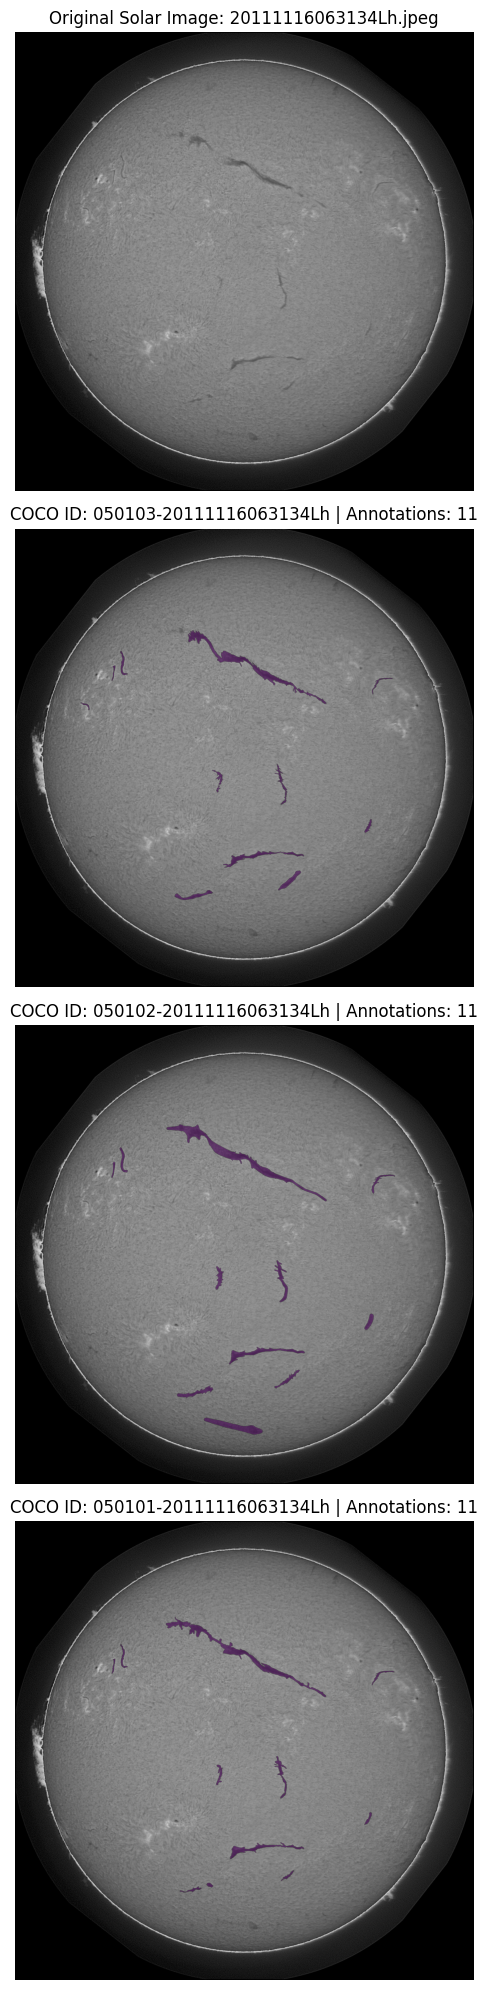

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import glob

# Pick one image that has multiple annotation records
filename = next(iter(duplicate_groups.keys()))
img_ids = duplicate_groups[filename]

# Locate the physical image
image_path = glob.glob(
    os.path.join(dataset_path, "**", filename),
    recursive=True
)[0]

image = np.array(Image.open(image_path).convert("RGB"))

# Display original image and annotation records
fig, axes = plt.subplots(
    1 + len(img_ids),
    1,
    figsize=(12, 5 * (1 + len(img_ids)))
)

axes[0].imshow(image)
axes[0].set_title(f"Original Solar Image: {filename}")
axes[0].axis("off")

for i, img_id in enumerate(img_ids, start=1):

    info = coco.imgs[img_id]
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[img_id]))

    axes[i].imshow(image)

    for ann in anns:
        mask = coco.annToMask(ann)

        # Transparent mask overlay
        axes[i].imshow(
            np.ma.masked_where(mask == 0, mask),
            alpha=0.6
        )

    axes[i].set_title(
        f"COCO ID: {img_id} | "
        f"Annotations: {len(anns)}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

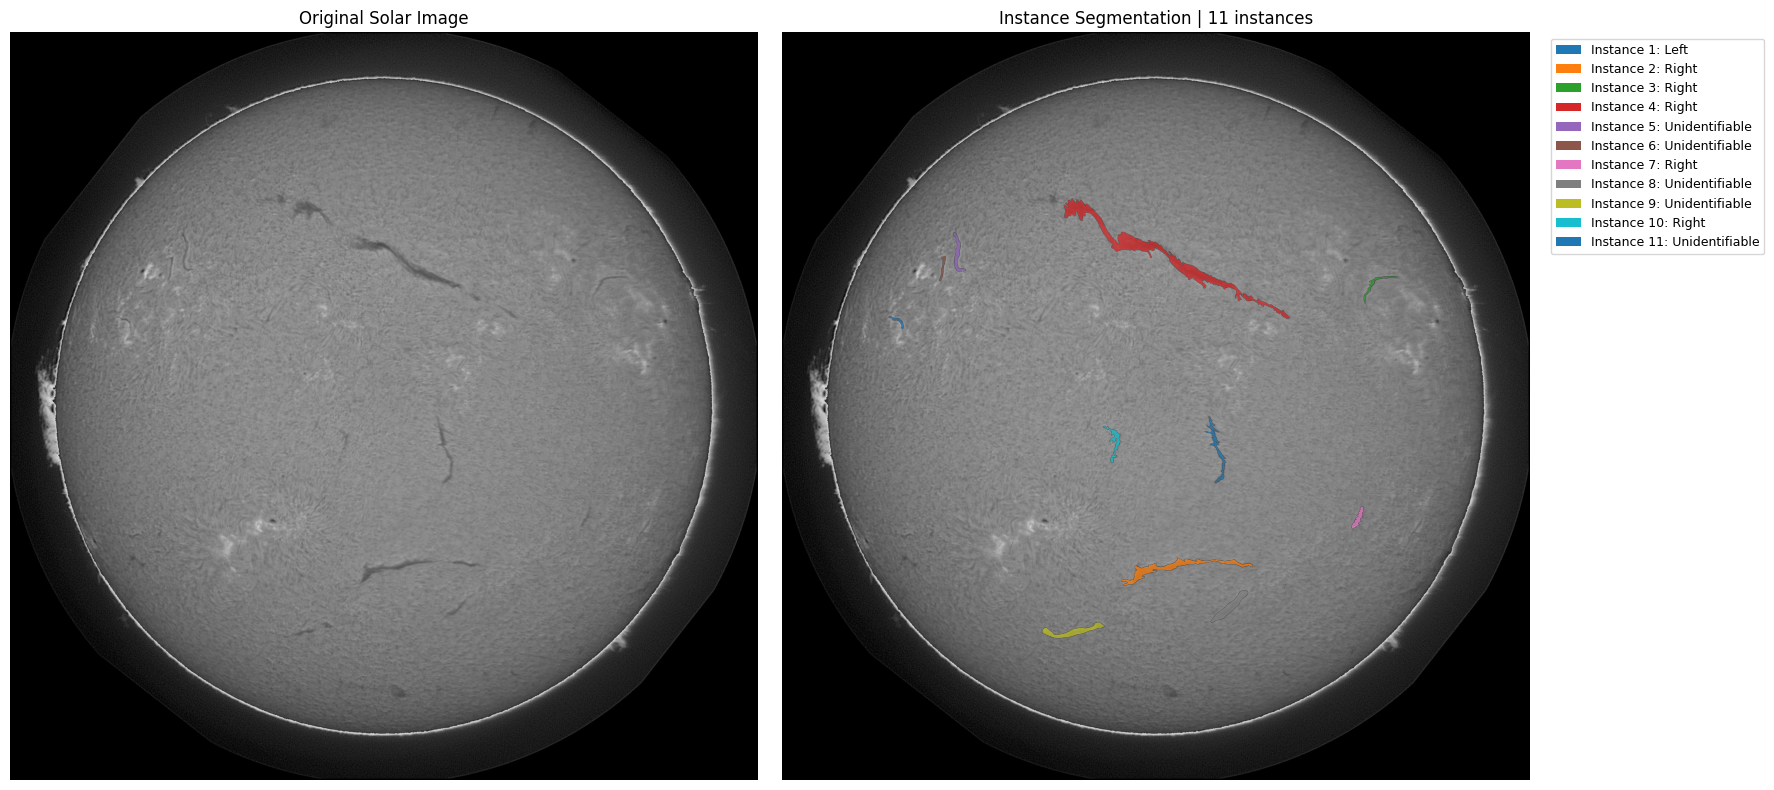

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from PIL import Image
import numpy as np
import os
import glob

# Select one of the duplicate image records
filename = next(iter(duplicate_groups.keys()))
img_id = duplicate_groups[filename][0]

# Load the physical image
image_path = glob.glob(
    os.path.join(dataset_path, "**", filename),
    recursive=True
)[0]

image = np.array(
    Image.open(image_path).convert("RGB")
)

# Load annotations for this COCO record
anns = coco.loadAnns(
    coco.getAnnIds(imgIds=[img_id])
)

# Distinct colors for each instance
colors = list(mcolors.TABLEAU_COLORS.values())

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8)
)

# Original image
axes[0].imshow(image)
axes[0].set_title("Original Solar Image")
axes[0].axis("off")

# Instance overlay
axes[1].imshow(image)

legend_handles = []

for idx, ann in enumerate(anns):

    mask = coco.annToMask(ann).astype(bool)

    color = colors[idx % len(colors)]

    colored_mask = np.zeros(
        (*mask.shape, 4),
        dtype=float
    )

    colored_mask[mask] = mcolors.to_rgba(
        color,
        alpha=0.75
    )

    axes[1].imshow(colored_mask)

    category_name = coco.cats[
        ann["category_id"]
    ]["name"]

    legend_handles.append(
        Patch(
            facecolor=color,
            label=f"Instance {idx + 1}: {category_name}"
        )
    )

axes[1].set_title(
    f"Instance Segmentation | {len(anns)} instances"
)

axes[1].axis("off")

axes[1].legend(
    handles=legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=9
)

plt.tight_layout()
plt.show()

In [ ]:
from collections import Counter
import numpy as np

all_ann_ids = coco.getAnnIds()
all_anns = coco.loadAnns(all_ann_ids)

category_counts = Counter()
instances_per_record = []
category_presence = Counter()

for img_id in coco.imgs:

    anns = coco.loadAnns(
        coco.getAnnIds(imgIds=[img_id])
    )

    instances_per_record.append(len(anns))

    for ann in anns:
        category_counts[ann["category_id"]] += 1
        category_presence[ann["category_id"]] += 1

print("TOTAL ANNOTATIONS:", len(all_anns))

print("\nANNOTATIONS PER CATEGORY:")
for cat_id, count in sorted(category_counts.items()):
    name = coco.cats[cat_id]["name"]
    print(f"{name} (ID {cat_id}): {count:,}")

print("\nINSTANCES PER IMAGE RECORD:")
print("Minimum:", min(instances_per_record))
print("Maximum:", max(instances_per_record))
print("Mean:", round(np.mean(instances_per_record), 2))
print("Median:", np.median(instances_per_record))

print("\nCATEGORY DISTRIBUTION:")
for cat_id in sorted(coco.cats):
    name = coco.cats[cat_id]["name"]
    percentage = (
        category_counts[cat_id] / len(all_anns)
    ) * 100

    print(f"{name}: {percentage:.2f}%")

TOTAL ANNOTATIONS: 8199

ANNOTATIONS PER CATEGORY:
Left (ID 1): 2,535
Right (ID 2): 2,590
Unidentifiable (ID 3): 3,074

INSTANCES PER IMAGE RECORD:
Minimum: 1
Maximum: 26
Mean: 7.1
Median: 7.0

CATEGORY DISTRIBUTION:
Left: 30.92%
Right: 31.59%
Unidentifiable: 37.49%
Ambiguous: 0.00%


In [ ]:
import numpy as np
from collections import defaultdict

category_areas = defaultdict(list)
category_widths = defaultdict(list)
category_heights = defaultdict(list)

for ann in all_anns:

    category_id = ann["category_id"]

    # COCO annotation area in pixels
    area = ann["area"]

    # COCO bounding box: [x, y, width, height]
    x, y, width, height = ann["bbox"]

    category_areas[category_id].append(area)
    category_widths[category_id].append(width)
    category_heights[category_id].append(height)


print("FILAMENT SIZE ANALYSIS")
print("=" * 65)

for category_id in sorted(coco.cats):

    name = coco.cats[category_id]["name"]
    areas = np.array(category_areas[category_id])

    if len(areas) == 0:
        print(f"\n{name}: No annotations")
        continue

    print(f"\n{name}")
    print("-" * 40)

    print("Instances:", len(areas))
    print("Minimum area:", round(areas.min(), 2))
    print("25th percentile:", round(np.percentile(areas, 25), 2))
    print("Median area:", round(np.median(areas), 2))
    print("75th percentile:", round(np.percentile(areas, 75), 2))
    print("Maximum area:", round(areas.max(), 2))

    print("Median bbox width:",
          round(np.median(category_widths[category_id]), 2))

    print("Median bbox height:",
          round(np.median(category_heights[category_id]), 2))


# Overall foreground size
all_areas = np.array([ann["area"] for ann in all_anns])

print("\n" + "=" * 65)
print("OVERALL AREA STATISTICS")
print("Mean:", round(all_areas.mean(), 2))
print("Median:", round(np.median(all_areas), 2))
print("90th percentile:", round(np.percentile(all_areas, 90), 2))

FILAMENT SIZE ANALYSIS

Left
----------------------------------------
Instances: 2535
Minimum area: 60.0
25th percentile: 840.0
Median area: 1438.0
75th percentile: 2756.5
Maximum area: 37739.0
Median bbox width: 87.3
Median bbox height: 85.44

Right
----------------------------------------
Instances: 2590
Minimum area: 9.0
25th percentile: 841.25
Median area: 1524.0
75th percentile: 2979.5
Maximum area: 21158.0
Median bbox width: 92.35
Median bbox height: 84.44

Unidentifiable
----------------------------------------
Instances: 3074
Minimum area: 73.0
25th percentile: 493.0
Median area: 868.5
75th percentile: 1726.0
Maximum area: 35251.0
Median bbox width: 55.21
Median bbox height: 50.48

Ambiguous: No annotations

OVERALL AREA STATISTICS
Mean: 2119.83
Median: 1228.0
90th percentile: 4684.6


In [ ]:
import numpy as np

bbox_widths = []
bbox_heights = []
aspect_ratios = []
bbox_areas = []
mask_areas = []

for ann in all_anns:

    x, y, width, height = ann["bbox"]

    bbox_widths.append(width)
    bbox_heights.append(height)

    aspect_ratios.append(
        max(width, height) / max(min(width, height), 1e-6)
    )

    bbox_areas.append(width * height)
    mask_areas.append(ann["area"])


def print_stats(name, values):

    values = np.array(values)

    print(f"\n{name}")
    print("Median:", round(np.median(values), 2))
    print("75th percentile:", round(np.percentile(values, 75), 2))
    print("90th percentile:", round(np.percentile(values, 90), 2))
    print("Maximum:", round(np.max(values), 2))


print_stats("Bounding box width", bbox_widths)
print_stats("Bounding box height", bbox_heights)
print_stats("Aspect ratio", aspect_ratios)
print_stats("Bounding box area", bbox_areas)

# How much of each bounding box is occupied by its filament?
occupancy = np.array(mask_areas) / np.maximum(
    np.array(bbox_areas), 1
)

print_stats("Bounding box occupancy (%)", occupancy * 100)

# Proportion of elongated instances
for threshold in [2, 3, 5]:

    percentage = (
        np.array(aspect_ratios) >= threshold
    ).mean() * 100

    print(
        f"Aspect ratio >= {threshold}: "
        f"{percentage:.2f}%"
    )


Bounding box width
Median: 74.52
75th percentile: 126.21
90th percentile: 202.48
Maximum: 1067.31

Bounding box height
Median: 69.61
75th percentile: 116.59
90th percentile: 186.51
Maximum: 709.81

Aspect ratio
Median: 1.66
75th percentile: 2.36
90th percentile: 3.23
Maximum: 12.78

Bounding box area
Median: 4999.78
75th percentile: 12731.08
90th percentile: 29544.75
Maximum: 385480.51

Bounding box occupancy (%)
Median: 24.3
75th percentile: 36.15
90th percentile: 47.79
Maximum: 87.54
Aspect ratio >= 2: 36.10%
Aspect ratio >= 3: 12.86%
Aspect ratio >= 5: 1.66%


In [ ]:
import numpy as np

PATCH_SIZES = [512, 768, 1024]

def get_patch_starts(image_size, patch_size, overlap):
    stride = patch_size - overlap

    starts = list(range(
        0,
        max(image_size - patch_size, 0) + 1,
        stride
    ))

    final_start = image_size - patch_size

    if starts[-1] != final_start:
        starts.append(final_start)

    return starts


def evaluate_patch_size(patch_size, overlap):

    starts_x = get_patch_starts(
        2048, patch_size, overlap
    )

    starts_y = get_patch_starts(
        2048, patch_size, overlap
    )

    contained = 0
    total = 0

    for ann in all_anns:

        x, y, width, height = ann["bbox"]

        x2 = x + width
        y2 = y + height

        total += 1

        fits = False

        for py in starts_y:
            for px in starts_x:

                if (
                    x >= px and
                    y >= py and
                    x2 <= px + patch_size and
                    y2 <= py + patch_size
                ):
                    fits = True
                    break

            if fits:
                break

        if fits:
            contained += 1

    return {
        "patch_size": patch_size,
        "overlap": overlap,
        "patches_per_image": len(starts_x) * len(starts_y),
        "contained": contained,
        "total": total,
        "percentage": contained / total * 100
    }


print("PATCH SIZE COMPARISON")
print("=" * 75)

for patch_size in PATCH_SIZES:

    overlap = patch_size // 4

    result = evaluate_patch_size(
        patch_size,
        overlap
    )

    print(
        f"\nPatch: {result['patch_size']} × {result['patch_size']}"
    )

    print("Overlap:", result["overlap"])
    print("Patches per image:", result["patches_per_image"])

    print(
        f"Instances full'y contained: "
        f"{result['contained']:,}/{result['total']:,}"
    )

    print(
        f"Containment rate: "
        f"{result['percentage']:.2f}%"
    )

PATCH SIZE COMPARISON

Patch: 512 × 512
Overlap: 128
Patches per image: 25
Instances full'y contained: 7,448/8,199
Containment rate: 90.84%

Patch: 768 × 768
Overlap: 192
Patches per image: 16
Instances full'y contained: 7,944/8,199
Containment rate: 96.89%

Patch: 1024 × 1024
Overlap: 256
Patches per image: 9
Instances full'y contained: 8,095/8,199
Containment rate: 98.73%


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    properties = torch.cuda.get_device_properties(0)

    print(
        "GPU memory:",
        round(properties.total_memory / (1024 ** 3), 2),
        "GB"
    )

    print(
        "CUDA capability:",
        properties.major,
        properties.minor
    )

else:
    print("Running on CPU")


PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
GPU memory: 79.25 GB
CUDA capability: 8 0


In [ ]:
import os
import glob
import numpy as np
from PIL import Image
from collections import Counter

image_modes = Counter()
image_formats = Counter()
image_sizes = Counter()

pixel_stats = []

sample_ids = list(coco.imgs.keys())[:20]

for img_id in sample_ids:

    info = coco.imgs[img_id]
    filename = info["file_name"]

    paths = glob.glob(
        os.path.join(dataset_path, "**", filename),
        recursive=True
    )

    if not paths:
        print("MISSING:", filename)
        continue

    with Image.open(paths[0]) as img:

        image_modes[img.mode] += 1
        image_formats[img.format] += 1
        image_sizes[img.size] += 1

        arr = np.asarray(img)

        pixel_stats.append({
            "min": arr.min(),
            "max": arr.max(),
            "mean": arr.mean(),
            "std": arr.std(),
            "shape": arr.shape
        })

print("IMAGE MODES:", image_modes)
print("IMAGE FORMATS:", image_formats)
print("IMAGE SIZES:", image_sizes)

print("\nPIXEL STATISTICS (20 samples)")

for key in ["min", "max", "mean", "std"]:
    values = [s[key] for s in pixel_stats]
    print(f"{key}: {np.mean(values):.2f} average")

print("\nSAMPLE ARRAY SHAPES:")
for shape in Counter(s["shape"] for s in pixel_stats):
    print(shape)

IMAGE MODES: Counter({'L': 20})
IMAGE FORMATS: Counter({'JPEG': 20})
IMAGE SIZES: Counter({(2048, 2048): 20})

PIXEL STATISTICS (20 samples)
min: 0.00 average
max: 239.50 average
mean: 83.09 average
std: 55.40 average

SAMPLE ARRAY SHAPES:
(2048, 2048)


In [ ]:
import os
import glob
from collections import Counter

missing_files = []
resolved_files = {}

for img_id, info in coco.imgs.items():

    filename = info["file_name"]

    if filename not in resolved_files:

        paths = glob.glob(
            os.path.join(dataset_path, "**", filename),
            recursive=True
        )

        if paths:
            resolved_files[filename] = paths[0]
        else:
            missing_files.append(filename)

print("Unique filenames:", len(filename_to_ids))
print("Resolved physical images:", len(resolved_files))
print("Missing physical images:", len(set(missing_files)))

print("\nExample resolved paths:")
for filename, path in list(resolved_files.items())[:5]:
    print(filename, "->", path)

print("\nImage path distribution:")
print(Counter(
    os.path.dirname(path)
    for path in resolved_files.values()
).most_common(10))

Unique filenames: 707
Resolved physical images: 707
Missing physical images: 0

Example resolved paths:
20140609195854Bh.jpeg -> /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20140609195854Bh.jpeg
20111116063134Lh.jpeg -> /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20111116063134Lh.jpeg
20130725122934Ch.jpeg -> /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20130725122934Ch.jpeg
20141027025054Uh.jpeg -> /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20141027025054Uh.jpeg
20160714235434Lh.jpeg -> /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20160714235434Lh.jpeg

Image path distribution:
[('/root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_ima

In [ ]:
import numpy as np
from collections import Counter

overlap_records = []
empty_masks = []
invalid_masks = []

total_instances = 0
total_records = 0

for img_id, info in coco.imgs.items():

    anns = coco.loadAnns(
        coco.getAnnIds(imgIds=[img_id])
    )

    total_records += 1

    occupied = np.zeros(
        (info["height"], info["width"]),
        dtype=bool
    )

    record_overlap_pixels = 0

    for ann in anns:

        total_instances += 1

        try:
            mask = coco.annToMask(ann).astype(bool)

            if not mask.any():
                empty_masks.append(ann["id"])
                continue

            # Count pixels already occupied by another instance
            overlap = occupied & mask

            record_overlap_pixels += int(overlap.sum())

            occupied |= mask

        except Exception as exc:
            invalid_masks.append((ann["id"], str(exc)))

    if record_overlap_pixels > 0:
        overlap_records.append({
            "image_id": img_id,
            "filename": info["file_name"],
            "overlap_pixels": record_overlap_pixels
        })

print("INSTANCE MASK INTEGRITY AUDIT")
print("=" * 50)

print("COCO records:", total_records)
print("Instances inspected:", total_instances)
print("Records with overlapping instances:", len(overlap_records))
print("Empty masks:", len(empty_masks))
print("Invalid masks:", len(invalid_masks))

if overlap_records:
    print("\nFirst 10 overlapping records:")
    for record in overlap_records[:10]:
        print(record)

INSTANCE MASK INTEGRITY AUDIT
COCO records: 1154
Instances inspected: 8199
Records with overlapping instances: 5
Empty masks: 0
Invalid masks: 0

First 10 overlapping records:
{'image_id': '010403-20160810234034Lh', 'filename': '20160810234034Lh.jpeg', 'overlap_pixels': 4970}
{'image_id': '050102-20150116082034Lh', 'filename': '20150116082034Lh.jpeg', 'overlap_pixels': 1}
{'image_id': '010403-20150228082414Th', 'filename': '20150228082414Th.jpeg', 'overlap_pixels': 9}
{'image_id': '050202-20120523163014Mh', 'filename': '20120523163014Mh.jpeg', 'overlap_pixels': 60}
{'image_id': '030101-20210815140550Bh', 'filename': '20210815140550Bh.jpeg', 'overlap_pixels': 1}


In [ ]:
import numpy as np

overlap_image_ids = [
    "010403-20160810234034Lh",
    "050102-20150116082034Lh",
    "010403-20150228082414Th",
    "050202-20120523163014Mh",
    "030101-20210815140550Bh"
]

print("PAIRWISE INSTANCE OVERLAP ANALYSIS")
print("=" * 75)

for img_id in overlap_image_ids:

    info = coco.imgs[img_id]

    anns = coco.loadAnns(
        coco.getAnnIds(imgIds=[img_id])
    )

    masks = []

    for ann in anns:
        mask = coco.annToMask(ann).astype(bool)
        masks.append(mask)

    print(f"\nIMAGE: {info['file_name']}")
    print(f"COCO ID: {img_id}")
    print(f"Instances: {len(anns)}")

    for i in range(len(anns)):
        for j in range(i + 1, len(anns)):

            intersection = np.logical_and(
                masks[i], masks[j]
            ).sum()

            if intersection == 0:
                continue

            area_a = masks[i].sum()
            area_b = masks[j].sum()

            union = area_a + area_b - intersection

            iou = intersection / union

            category_a = coco.cats[
                anns[i]["category_id"]
            ]["name"]

            category_b = coco.cats[
                anns[j]["category_id"]
            ]["name"]

            print(f"\nInstance {i + 1} vs Instance {j + 1}")
            print(f"Categories: {category_a} vs {category_b}")
            print(f"Area A: {area_a:,}")
            print(f"Area B: {area_b:,}")
            print(f"Intersection: {intersection:,}")
            print(f"IoU: {iou:.6f}")
            print(
                "Overlap relative to smaller mask:",
                f"{intersection / min(area_a, area_b) * 100:.2f}%"
            )

PAIRWISE INSTANCE OVERLAP ANALYSIS

IMAGE: 20160810234034Lh.jpeg
COCO ID: 010403-20160810234034Lh
Instances: 8

Instance 1 vs Instance 2
Categories: Right vs Right
Area A: 5,874
Area B: 5,959
Intersection: 4,970
IoU: 0.724173
Overlap relative to smaller mask: 84.61%

IMAGE: 20150116082034Lh.jpeg
COCO ID: 050102-20150116082034Lh
Instances: 8

Instance 7 vs Instance 8
Categories: Unidentifiable vs Unidentifiable
Area A: 1,965
Area B: 1,557
Intersection: 1
IoU: 0.000284
Overlap relative to smaller mask: 0.06%

IMAGE: 20150228082414Th.jpeg
COCO ID: 010403-20150228082414Th
Instances: 11

Instance 9 vs Instance 11
Categories: Left vs Right
Area A: 1,745
Area B: 9
Intersection: 9
IoU: 0.005158
Overlap relative to smaller mask: 100.00%

IMAGE: 20120523163014Mh.jpeg
COCO ID: 050202-20120523163014Mh
Instances: 16

Instance 5 vs Instance 6
Categories: Left vs Left
Area A: 1,229
Area B: 60
Intersection: 60
IoU: 0.048820
Overlap relative to smaller mask: 100.00%

IMAGE: 20210815140550Bh.jpeg
COCO I

In [ ]:
img_id = "010403-20160810234034Lh"

anns = coco.loadAnns(
    coco.getAnnIds(imgIds=[img_id])
)

print("IMAGE:", coco.imgs[img_id])
print("=" * 70)

for idx in [0, 1]:

    ann = anns[idx]

    print(f"\nINSTANCE {idx + 1}")
    print("Annotation ID:", ann["id"])
    print("Category:", coco.cats[ann["category_id"]]["name"])
    print("Area:", ann["area"])
    print("Bounding box:", ann["bbox"])
    print("Is crowd:", ann.get("iscrowd"))
    print("Segmentation type:", type(ann["segmentation"]).__name__)

    segmentation = ann["segmentation"]

    if isinstance(segmentation, list):
        print("Number of polygons:", len(segmentation))
        print(
            "Polygon vertex counts:",
            [len(poly) // 2 for poly in segmentation]
        )

    elif isinstance(segmentation, dict):
        print("RLE keys:", segmentation.keys())

IMAGE: {'license': 1, 'file_name': '20160810234034Lh.jpeg', 'url': 'https://gong2.nso.edu/HA/hag/201608/20160810/20160810234034Lh.jpg', 'height': 2048, 'width': 2048, 'date_captured': '2016-08-10 23:40:34', 'id': '010403-20160810234034Lh'}

INSTANCE 1
Annotation ID: d38060a1-d7c7-459a-8048-abeb4d6fa7c4
Category: Right
Area: 5874.0
Bounding box: [751.0, 717.0, 72.0, 340.0]
Is crowd: 0
Segmentation type: list
Number of polygons: 1
Polygon vertex counts: [174]

INSTANCE 2
Annotation ID: 066551fe-8fe4-4678-bbeb-06782e5b3416
Category: Right
Area: 5959.0
Bounding box: [751.0, 720.0, 72.0, 340.0]
Is crowd: 0
Segmentation type: list
Number of polygons: 1
Polygon vertex counts: [196]


In [ ]:
from collections import defaultdict

high_overlap_pairs = []

for img_id in coco.getImgIds():
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[img_id]))

    if len(anns) < 2:
        continue

    masks = [
        coco.annToMask(ann).astype(bool)
        for ann in anns
    ]

    for i in range(len(anns)):
        for j in range(i + 1, len(anns)):
            intersection = (masks[i] & masks[j]).sum()

            if intersection == 0:
                continue

            union = (masks[i] | masks[j]).sum()
            iou = intersection / union

            if iou >= 0.50:
                high_overlap_pairs.append({
                    "image_id": img_id,
                    "filename": coco.loadImgs([img_id])[0]["file_name"],
                    "ann_a": anns[i]["id"],
                    "ann_b": anns[j]["id"],
                    "category_a": anns[i]["category_id"],
                    "category_b": anns[j]["category_id"],
                    "iou": round(float(iou), 4),
                    "area_a": anns[i]["area"],
                    "area_b": anns[j]["area"],
                })

print("Pairs with IoU >= 0.50:", len(high_overlap_pairs))
print("Unique images:", len(set(p["filename"] for p in high_overlap_pairs)))

for pair in sorted(high_overlap_pairs, key=lambda x: x["iou"], reverse=True):
    print(pair)

Pairs with IoU >= 0.50: 1
Unique images: 1
{'image_id': '010403-20160810234034Lh', 'filename': '20160810234034Lh.jpeg', 'ann_a': 'd38060a1-d7c7-459a-8048-abeb4d6fa7c4', 'ann_b': '066551fe-8fe4-4678-bbeb-06782e5b3416', 'category_a': 2, 'category_b': 2, 'iou': 0.7242, 'area_a': 5874.0, 'area_b': 5959.0}


In [ ]:
import os
import torch
import torchvision
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

# Verify compiled detection operators
try:
    from torchvision.ops import nms, roi_align
    boxes = torch.tensor([[0., 0., 10., 10.], [1., 1., 9., 9.]])
    scores = torch.tensor([0.9, 0.8])
    print("NMS test:", nms(boxes, scores, 0.5).tolist())

    x = torch.rand(1, 1, 16, 16)
    rois = torch.tensor([[0., 0., 0., 8., 8.]])
    print("ROI Align test:", roi_align(x, rois, output_size=(3, 3)).shape)
    print("Detection operators: OK")

except Exception as e:
    print("Detection operators FAILED:", repr(e))

# Inspect competition directory structure
root = Path(dataset_path)

print("\nDataset root:", root)
for path in sorted(root.iterdir()):
    if path.is_dir():
        files = list(path.iterdir())
        print(f"{path.name}/ — {len(files)} entries")
        for child in files[:5]:
            print("  ", child.name)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
CUDA: True
GPU: NVIDIA A100-SXM4-80GB
NMS test: [0]
ROI Align test: torch.Size([1, 1, 3, 3])
Detection operators: OK

Dataset root: /root/.cache/kagglehub/competitions/filament-segmentation-2026
MAGFiLO_1.0_Kaggle_2026/ — 2 entries
   train
   test


In [ ]:
from pathlib import Path

competition_root = Path(dataset_path) / "MAGFiLO_1.0_Kaggle_2026"

for split in ["train", "test"]:
    split_path = competition_root / split

    print(f"\n{'=' * 60}")
    print(f"{split.upper()} DIRECTORY")
    print(f"{'=' * 60}")

    for path in sorted(split_path.rglob("*")):
        if path.is_file():
            print(
                f"{path.relative_to(split_path)} "
                f"({path.stat().st_size / (1024 * 1024):.2f} MB)"
            )


TRAIN DIRECTORY
MAGFiLO_1.0_Annotations_kaggle2026_train.json (46.36 MB)
train_images/20110109104734Ch.jpeg (0.83 MB)
train_images/20110114105034Ch.jpeg (0.83 MB)
train_images/20110119082634Lh.jpeg (0.71 MB)
train_images/20110123174914Mh.jpeg (0.58 MB)
train_images/20110128174814Mh.jpeg (0.59 MB)
train_images/20110203082634Lh.jpeg (0.72 MB)
train_images/20110205082634Lh.jpeg (0.71 MB)
train_images/20110211084114Th.jpeg (0.65 MB)
train_images/20110213093414Th.jpeg (0.66 MB)
train_images/20110215083814Th.jpeg (0.66 MB)
train_images/20110220082634Lh.jpeg (0.72 MB)
train_images/20110221173814Mh.jpeg (0.58 MB)
train_images/20110301082654Uh.jpeg (0.73 MB)
train_images/20110306082634Lh.jpeg (0.72 MB)
train_images/20110312082634Lh.jpeg (0.74 MB)
train_images/20110313082654Uh.jpeg (0.71 MB)
train_images/20110317082654Uh.jpeg (0.72 MB)
train_images/20110322005814Mh.jpeg (0.71 MB)
train_images/20110324082614Th.jpeg (0.70 MB)
train_images/20110325171014Mh.jpeg (0.73 MB)
train_images/2011032617091

In [ ]:
import os

print("\nCompetition files:")
for name in sorted(os.listdir(Path(dataset_path).parent)):
    print(name)


Competition files:
filament-segmentation-2026
filament-segmentation-2026.complete


In [ ]:
from pathlib import Path
from PIL import Image
import json

competition_root = Path(dataset_path) / "MAGFiLO_1.0_Kaggle_2026"

train_dir = competition_root / "train" / "train_images"
test_dir = competition_root / "test" / "test_images"

ann_path = (
    competition_root / "train" /
    "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
)

train_images = sorted(train_dir.glob("*.jpeg"))
test_images = sorted(test_dir.glob("*.jpeg"))

print("TRAIN IMAGES:", len(train_images))
print("TEST IMAGES:", len(test_images))
print("ANNOTATION FILE EXISTS:", ann_path.exists())

with open(ann_path) as f:
    annotation_data = json.load(f)

print("\nANNOTATION JSON KEYS:", annotation_data.keys())
print("COCO IMAGE RECORDS:", len(annotation_data["images"]))
print("ANNOTATIONS:", len(annotation_data["annotations"]))

print("\nTRAIN IMAGE EXAMPLE:")
print(train_images[0])

print("\nTEST IMAGE EXAMPLE:")
print(test_images[0])

print("\nIMAGE SHAPE:")
with Image.open(train_images[0]) as img:
    print(img.mode, img.size)

with Image.open(test_images[0]) as img:
    print(img.mode, img.size)

TRAIN IMAGES: 707
TEST IMAGES: 180
ANNOTATION FILE EXISTS: True

ANNOTATION JSON KEYS: dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
COCO IMAGE RECORDS: 1154
ANNOTATIONS: 8199

TRAIN IMAGE EXAMPLE:
/root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/train_images/20110109104734Ch.jpeg

TEST IMAGE EXAMPLE:
/root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images/20110120105534Ch.jpeg

IMAGE SHAPE:
L (2048, 2048)
L (2048, 2048)


In [ ]:
from collections import defaultdict
import numpy as np

IMAGE_SIZE = 2048
PATCH_SIZE = 768
OVERLAP = 192
STRIDE = PATCH_SIZE - OVERLAP

# Generate patch positions and ensure the final patches reach image edges.
positions = list(range(0, IMAGE_SIZE - PATCH_SIZE + 1, STRIDE))

if positions[-1] != IMAGE_SIZE - PATCH_SIZE:
    positions.append(IMAGE_SIZE - PATCH_SIZE)

print("Patch positions:", positions)
print("Patches per image:", len(positions) ** 2)

patches = [
    (x, y, x + PATCH_SIZE, y + PATCH_SIZE)
    for y in positions
    for x in positions
]

# Audit all annotation records.
stats = defaultdict(int)

for img_id in coco.getImgIds():
    anns = coco.loadAnns(coco.getAnnIds(imgIds=[img_id]))

    for ann in anns:
        x, y, w, h = ann["bbox"]
        x2, y2 = x + w, y + h

        fully_contained = False
        intersects = False

        for px1, py1, px2, py2 in patches:
            intersection_w = max(0, min(x2, px2) - max(x, px1))
            intersection_h = max(0, min(y2, py2) - max(y, py1))

            if intersection_w > 0 and intersection_h > 0:
                intersects = True

            if x >= px1 and y >= py1 and x2 <= px2 and y2 <= py2:
                fully_contained = True

        if fully_contained:
            stats["fully_contained"] += 1
        elif intersects:
            stats["boundary_crossing"] += 1
        else:
            stats["not_intersecting"] += 1

total = sum(stats.values())

print("\nINSTANCE COVERAGE")
print("Total instances:", total)

for key, value in stats.items():
    print(f"{key}: {value} ({value / total * 100:.2f}%)")

Patch positions: [0, 576, 1152, 1280]
Patches per image: 16

INSTANCE COVERAGE
Total instances: 8199
fully_contained: 7944 (96.89%)
boundary_crossing: 255 (3.11%)


In [ ]:
import random
import numpy as np
import torch

from torch.utils.data import Dataset
from PIL import Image

IMAGE_SIZE = 2048
PATCH_SIZE = 768
OVERLAP = 192
STRIDE = PATCH_SIZE - OVERLAP

PATCH_POSITIONS = list(range(0, IMAGE_SIZE - PATCH_SIZE + 1, STRIDE))

if PATCH_POSITIONS[-1] != IMAGE_SIZE - PATCH_SIZE:
    PATCH_POSITIONS.append(IMAGE_SIZE - PATCH_SIZE)

PATCH_COORDS = [
    (x, y)
    for y in PATCH_POSITIONS
    for x in PATCH_POSITIONS
]


class SolarFilamentDataset(Dataset):
    def __init__(
        self,
        filenames,
        filename_to_ids,
        coco,
        image_dir,
        patches_per_image=None,
        training=True
    ):
        self.filenames = list(filenames)
        self.filename_to_ids = filename_to_ids
        self.coco = coco
        self.image_dir = image_dir
        self.training = training

        self.patches_per_image = (
            patches_per_image
            if patches_per_image is not None
            else len(PATCH_COORDS)
        )

        self.image_records = {}

        for filename in self.filenames:
            ids = self.filename_to_ids[filename]
            self.image_records[filename] = ids

        self.patch_index = []

        for filename in self.filenames:
            for patch_idx in range(self.patches_per_image):
                self.patch_index.append((filename, patch_idx))

    def __len__(self):
        return len(self.patch_index)

    def __getitem__(self, index):
        filename, patch_idx = self.patch_index[index]

        image_path = f"{self.image_dir}/{filename}"

        image = np.asarray(
            Image.open(image_path).convert("L"),
            dtype=np.float32
        ) / 255.0

        # Select one annotation record for this physical image.
        record_ids = self.image_records[filename]

        if self.training:
            image_id = random.choice(record_ids)
        else:
            image_id = record_ids[0]

        anns = self.coco.loadAnns(
            self.coco.getAnnIds(imgIds=[image_id])
        )

        px, py = PATCH_COORDS[patch_idx]

        image_patch = image[
            py:py + PATCH_SIZE,
            px:px + PATCH_SIZE
        ]

        masks = []
        boxes = []
        labels = []
        ignore_mask = np.zeros(
            (PATCH_SIZE, PATCH_SIZE),
            dtype=np.uint8
        )

        for ann in anns:
            x, y, w, h = ann["bbox"]
            x2, y2 = x + w, y + h

            full_mask = self.coco.annToMask(ann)

            patch_mask = full_mask[
                py:py + PATCH_SIZE,
                px:px + PATCH_SIZE
            ]

            if patch_mask.sum() == 0:
                continue

            fully_contained = (
                x >= px and
                y >= py and
                x2 <= px + PATCH_SIZE and
                y2 <= py + PATCH_SIZE
            )

            if not fully_contained:
                ignore_mask |= patch_mask.astype(np.uint8)
                continue

            ys, xs = np.where(patch_mask)

            if len(xs) == 0:
                continue

            masks.append(patch_mask.astype(np.uint8))

            boxes.append([
                float(xs.min()),
                float(ys.min()),
                float(xs.max() + 1),
                float(ys.max() + 1)
            ])

            labels.append(1)

        if masks:
            masks = torch.as_tensor(
                np.stack(masks),
                dtype=torch.uint8
            )
            boxes = torch.as_tensor(
                boxes,
                dtype=torch.float32
            )
            labels = torch.as_tensor(
                labels,
                dtype=torch.int64
            )
        else:
            masks = torch.zeros(
                (0, PATCH_SIZE, PATCH_SIZE),
                dtype=torch.uint8
            )
            boxes = torch.zeros(
                (0, 4),
                dtype=torch.float32
            )
            labels = torch.zeros(
                (0,),
                dtype=torch.int64
            )

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": torch.tensor([index]),
            "area": (
                masks.sum(dim=(1, 2)).float()
                if len(masks) > 0
                else torch.zeros((0,), dtype=torch.float32)
            ),
            "iscrowd": torch.zeros(
                (len(masks),),
                dtype=torch.int64
            ),
            "ignore_mask": torch.as_tensor(
                ignore_mask,
                dtype=torch.uint8
            )
        }

        image_tensor = torch.from_numpy(
            image_patch.copy()
        ).unsqueeze(0)

        return image_tensor, target

In [ ]:
from collections import defaultdict
import numpy as np

PATCH_SIZE = 768

valid_patches_by_filename = {}
instance_coverage = defaultdict(int)

total_patches = 0
valid_patch_count = 0
images_without_valid_patches = []
instances_without_clean_coverage = []

for filename in unique_filenames:
    record_ids = filename_to_ids[filename]

    # Collect every bounding box across all annotation records
    all_boxes = []

    for image_id in record_ids:
        anns = coco.loadAnns(coco.getAnnIds(imgIds=[image_id]))

        for ann in anns:
            x, y, w, h = ann["bbox"]
            all_boxes.append({
                "image_id": image_id,
                "ann_id": ann["id"],
                "bbox": (x, y, x + w, y + h)
            })

    valid_patch_indices = []

    for patch_idx, (px, py) in enumerate(PATCH_COORDS):
        px2 = px + PATCH_SIZE
        py2 = py + PATCH_SIZE

        patch_is_valid = True

        for item in all_boxes:
            x1, y1, x2, y2 = item["bbox"]

            intersects = (
                max(x1, px) < min(x2, px2) and
                max(y1, py) < min(y2, py2)
            )

            fully_contained = (
                x1 >= px and y1 >= py and
                x2 <= px2 and y2 <= py2
            )

            if intersects and not fully_contained:
                patch_is_valid = False
                break

        if patch_is_valid:
            valid_patch_indices.append(patch_idx)

    valid_patches_by_filename[filename] = valid_patch_indices

    total_patches += len(PATCH_COORDS)
    valid_patch_count += len(valid_patch_indices)

    if not valid_patch_indices:
        images_without_valid_patches.append(filename)

    # Check every annotation instance has at least one clean patch
    for item in all_boxes:
        x1, y1, x2, y2 = item["bbox"]

        has_clean_coverage = any(
            x1 >= PATCH_COORDS[idx][0]
            and y1 >= PATCH_COORDS[idx][1]
            and x2 <= PATCH_COORDS[idx][0] + PATCH_SIZE
            and y2 <= PATCH_COORDS[idx][1] + PATCH_SIZE
            for idx in valid_patch_indices
        )

        if has_clean_coverage:
            instance_coverage["covered"] += 1
        else:
            instance_coverage["uncovered"] += 1
            instances_without_clean_coverage.append(
                (filename, item["image_id"], item["ann_id"])
            )

print("PATCH AUDIT")
print("Total possible patches:", total_patches)
print("Valid patches:", valid_patch_count)
print("Excluded patches:", total_patches - valid_patch_count)
print("Valid patch percentage:", round(valid_patch_count / total_patches * 100, 2))

print("\nIMAGE AUDIT")
print("Images with no valid patches:", len(images_without_valid_patches))

print("\nINSTANCE COVERAGE")
print("Fully covered instances:", instance_coverage["covered"])
print("Without clean coverage:", instance_coverage["uncovered"])

PATCH AUDIT
Total possible patches: 11312
Valid patches: 6269
Excluded patches: 5043
Valid patch percentage: 55.42

IMAGE AUDIT
Images with no valid patches: 4

INSTANCE COVERAGE
Fully covered instances: 4070
Without clean coverage: 4129


In [ ]:
import numpy as np

def audit_patch_strategy(patch_size, overlap):
    stride = patch_size - overlap
    positions = list(range(0, 2048 - patch_size + 1, stride))

    if positions[-1] != 2048 - patch_size:
        positions.append(2048 - patch_size)

    patches = [
        (x, y, x + patch_size, y + patch_size)
        for y in positions
        for x in positions
    ]

    total_patches = 0
    valid_patches = 0
    total_instances = 0
    covered_instances = 0
    images_without_valid_patches = 0

    for filename in unique_filenames:
        boxes = []

        for image_id in filename_to_ids[filename]:
            anns = coco.loadAnns(coco.getAnnIds(imgIds=[image_id]))

            for ann in anns:
                x, y, w, h = ann["bbox"]
                boxes.append((x, y, x + w, y + h))

        image_valid_patches = []

        for patch_idx, (px1, py1, px2, py2) in enumerate(patches):
            valid = True

            for x1, y1, x2, y2 in boxes:
                intersects = (
                    max(x1, px1) < min(x2, px2)
                    and max(y1, py1) < min(y2, py2)
                )

                contained = (
                    x1 >= px1 and y1 >= py1
                    and x2 <= px2 and y2 <= py2
                )

                if intersects and not contained:
                    valid = False
                    break

            if valid:
                image_valid_patches.append(patch_idx)

        total_patches += len(patches)
        valid_patches += len(image_valid_patches)

        if not image_valid_patches:
            images_without_valid_patches += 1

        for x1, y1, x2, y2 in boxes:
            total_instances += 1

            if any(
                x1 >= patches[idx][0]
                and y1 >= patches[idx][1]
                and x2 <= patches[idx][2]
                and y2 <= patches[idx][3]
                for idx in image_valid_patches
            ):
                covered_instances += 1

    return {
        "patch_size": patch_size,
        "overlap": overlap,
        "patches_per_image": len(patches),
        "valid_patches": valid_patches,
        "total_patches": total_patches,
        "valid_patch_pct": round(100 * valid_patches / total_patches, 2),
        "covered_instances": covered_instances,
        "total_instances": total_instances,
        "instance_coverage_pct": round(
            100 * covered_instances / total_instances, 2
        ),
        "images_without_valid_patches": images_without_valid_patches
    }


for config in [(768, 192), (1024, 256)]:
    print(audit_patch_strategy(*config))

{'patch_size': 768, 'overlap': 192, 'patches_per_image': 16, 'valid_patches': 6269, 'total_patches': 11312, 'valid_patch_pct': 55.42, 'covered_instances': 4070, 'total_instances': 8199, 'instance_coverage_pct': 49.64, 'images_without_valid_patches': 4}
{'patch_size': 1024, 'overlap': 256, 'patches_per_image': 9, 'valid_patches': 3405, 'total_patches': 6363, 'valid_patch_pct': 53.51, 'covered_instances': 5163, 'total_instances': 8199, 'instance_coverage_pct': 62.97, 'images_without_valid_patches': 46}


In [ ]:
from collections import OrderedDict
import numpy as np
import torch
from torch.utils.data import Dataset
from pathlib import Path
from PIL import Image

class SolarFilamentDataset(Dataset):
    def __init__(
        self,
        filenames,
        filename_to_ids,
        coco,
        image_dir,
        training=True,
        cache_size=4
    ):
        self.filenames = list(filenames)
        self.filename_to_ids = filename_to_ids
        self.coco = coco
        self.image_dir = Path(image_dir)
        self.training = training
        self.cache_size = cache_size

        self.patch_index = [
            (filename, patch_idx)
            for filename in self.filenames
            for patch_idx in range(len(PATCH_COORDS))
        ]

        self.cache = OrderedDict()
        self.set_epoch(0)

    def set_epoch(self, epoch):
        self.epoch = epoch

        if self.training:
            self.record_selection = {
                filename: random.choice(self.filename_to_ids[filename])
                for filename in self.filenames
            }
        else:
            self.record_selection = {
                filename: self.filename_to_ids[filename][0]
                for filename in self.filenames
            }

        # Clear cached records when the selected annotation sets change.
        self.cache.clear()

    def __len__(self):
        return len(self.patch_index)

    def _load_image_and_masks(self, filename, image_id):
        key = (filename, image_id)

        if key in self.cache:
            self.cache.move_to_end(key)
            return self.cache[key]

        image = np.asarray(
            Image.open(self.image_dir / filename).convert("L"),
            dtype=np.float32
        ) / 255.0

        anns = self.coco.loadAnns(
            self.coco.getAnnIds(imgIds=[image_id])
        )

        masks = [
            self.coco.annToMask(ann)
            for ann in anns
        ]

        result = (image, masks)

        self.cache[key] = result
        self.cache.move_to_end(key)

        if len(self.cache) > self.cache_size:
            self.cache.popitem(last=False)

        return result

    def __getitem__(self, index):
        filename, patch_idx = self.patch_index[index]
        image_id = self.record_selection[filename]

        image, full_masks = self._load_image_and_masks(
            filename,
            image_id
        )

        px, py = PATCH_COORDS[patch_idx]

        image_patch = image[
            py:py + PATCH_SIZE,
            px:px + PATCH_SIZE
        ]

        masks = []
        boxes = []

        for full_mask in full_masks:
            patch_mask = full_mask[
                py:py + PATCH_SIZE,
                px:px + PATCH_SIZE
            ]

            if not patch_mask.any():
                continue

            ys, xs = np.where(patch_mask)

            masks.append(patch_mask.astype(np.uint8))

            boxes.append([
                float(xs.min()),
                float(ys.min()),
                float(xs.max() + 1),
                float(ys.max() + 1)
            ])

        if masks:
            masks = torch.as_tensor(
                np.stack(masks),
                dtype=torch.uint8
            )
            boxes = torch.as_tensor(
                boxes,
                dtype=torch.float32
            )
        else:
            masks = torch.zeros(
                (0, PATCH_SIZE, PATCH_SIZE),
                dtype=torch.uint8
            )
            boxes = torch.zeros((0, 4), dtype=torch.float32)

        target = {
            "boxes": boxes,
            "labels": torch.ones(len(masks), dtype=torch.int64),
            "masks": masks,
            "image_id": torch.tensor([index]),
            "area": masks.sum(dim=(1, 2)).float(),
            "iscrowd": torch.zeros(len(masks), dtype=torch.int64)
        }

        image_tensor = torch.from_numpy(
            image_patch.copy()
        ).unsqueeze(0)

        return image_tensor, target

In [ ]:
train_dataset = SolarFilamentDataset(
    train_filenames,
    filename_to_ids,
    coco,
    train_dir,
    training=True,
    cache_size=4
)

val_dataset = SolarFilamentDataset(
    val_filenames,
    filename_to_ids,
    coco,
    train_dir,
    training=False,
    cache_size=4
)


In [ ]:
import random
import numpy as np

random.seed(42)

sample_indices = random.sample(
    range(len(train_dataset)),
    min(200, len(train_dataset))
)

positive_count = 0
negative_count = 0
instance_counts = []
positive_examples = []

for idx in sample_indices:
    image, target = train_dataset[idx]

    num_instances = len(target["masks"])

    if num_instances > 0:
        positive_count += 1
        instance_counts.append(num_instances)

        if len(positive_examples) < 5:
            positive_examples.append(idx)
    else:
        negative_count += 1

print("PATCH DISTRIBUTION")
print("Positive patches:", positive_count)
print("Negative patches:", negative_count)
print("Positive percentage:", round(positive_count / len(sample_indices) * 100, 2))

if instance_counts:
    print("\nINSTANCE COUNTS")
    print("Mean:", round(np.mean(instance_counts), 2))
    print("Median:", np.median(instance_counts))
    print("Maximum:", max(instance_counts))

print("\nPOSITIVE EXAMPLE INDICES:", positive_examples)

PATCH DISTRIBUTION
Positive patches: 142
Negative patches: 58
Positive percentage: 71.0

INSTANCE COUNTS
Mean: 2.28
Median: 2.0
Maximum: 7

POSITIVE EXAMPLE INDICES: [1824, 409, 4506, 4012, 3657]


In [ ]:
idx = positive_examples[0]

image, target = train_dataset[idx]

print("Patch index:", idx)
print("Image shape:", image.shape)
print("Instances:", len(target["masks"]))
print("Boxes shape:", target["boxes"].shape)
print("Masks shape:", target["masks"].shape)

assert image.shape == (1, 768, 768)
assert target["boxes"].shape == (len(target["masks"]), 4)
assert target["labels"].shape[0] == len(target["masks"])
assert torch.isfinite(target["boxes"]).all()

if len(target["boxes"]) > 0:
    assert (target["boxes"][:, 2:] > target["boxes"][:, :2]).all()
    assert (target["boxes"] >= 0).all()
    assert (target["boxes"] <= 768).all()

print("Positive sample integrity: PASSED")

Patch index: 1824
Image shape: torch.Size([1, 768, 768])
Instances: 1
Boxes shape: torch.Size([1, 4])
Masks shape: torch.Size([1, 768, 768])
Positive sample integrity: PASSED


In [ ]:
import torch
import torchvision

from torchvision.models.detection import (
    maskrcnn_resnet50_fpn,
    MaskRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

# Reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device("cuda")

# Load COCO-pretrained Mask R-CNN
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

model = maskrcnn_resnet50_fpn(
    weights=weights,
    min_size=768,
    max_size=768,
    box_detections_per_img=100
)

# Adapt ResNet's first convolution from RGB to grayscale
old_conv = model.backbone.body.conv1

new_conv = torch.nn.Conv2d(
    in_channels=1,
    out_channels=old_conv.out_channels,
    kernel_size=old_conv.kernel_size,
    stride=old_conv.stride,
    padding=old_conv.padding,
    bias=False
)

with torch.no_grad():
    new_conv.weight.copy_(
        old_conv.weight.mean(dim=1, keepdim=True)
    )

model.backbone.body.conv1 = new_conv

# Replace the box prediction head
num_classes = 2  # Background + filament

box_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    box_features,
    num_classes
)

# Replace the instance-mask prediction head
mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    mask_features,
    256,
    num_classes
)

# Configure grayscale normalization
model.transform.image_mean = [0.326]
model.transform.image_std = [0.217]

model = model.to(device)

print("Model initialized successfully")
print("Input channels:", model.backbone.body.conv1.in_channels)
print("Output classes:", model.roi_heads.box_predictor.cls_score.out_features)
print("Device:", device)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 240MB/s]


Model initialized successfully
Input channels: 1
Output classes: 2
Device: cuda
Trainable parameters: 43,703,131
Total parameters: 43,916,123


In [ ]:
import gc

model.train()

# Find a positive training patch
sample = None

for idx in range(len(train_dataset)):
    candidate_image, candidate_target = train_dataset[idx]

    if len(candidate_target["masks"]) > 0:
        sample = (candidate_image, candidate_target)
        print("Selected positive patch:", idx)
        break

assert sample is not None, "No positive patch found"

image, target = sample

image = image.to(device)

target = {
    key: value.to(device) if torch.is_tensor(value) else value
    for key, value in target.items()
}

# Optimizer for the initial training configuration
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scaler = torch.amp.GradScaler("cuda")

optimizer.zero_grad(set_to_none=True)

torch.cuda.reset_peak_memory_stats()

try:
    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        loss_dict = model([image], [target])
        total_loss = sum(loss for loss in loss_dict.values())

    print("\nLOSS COMPONENTS")

    for name, value in loss_dict.items():
        print(f"{name}: {value.item():.5f}")

    print("Total loss:", total_loss.item())

    scaler.scale(total_loss).backward()

    print("\nBackward pass: PASSED")

    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

    scaler.step(optimizer)
    scaler.update()

    print("Optimizer step: PASSED")

except torch.cuda.OutOfMemoryError:
    print("CUDA OUT OF MEMORY")
    raise

finally:
    optimizer.zero_grad(set_to_none=True)
    del image, target, sample
    gc.collect()
    torch.cuda.empty_cache()

Selected positive patch: 4

LOSS COMPONENTS
loss_classifier: 0.87631
loss_box_reg: 0.05394
loss_mask: 2.73556
loss_objectness: 0.22433
loss_rpn_box_reg: 0.01286
Total loss: 3.903001546859741

Backward pass: PASSED
Peak GPU memory: 1.17 GB
Optimizer step: PASSED


In [ ]:
from torch.utils.data import DataLoader

def detection_collate_fn(batch):
    return tuple(zip(*batch))

train_loader_test = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn
)

images, targets = next(iter(train_loader_test))

images = [img.to(device) for img in images]
targets = [
    {k: v.to(device) for k, v in target.items()}
    for target in targets
]

model.train()
optimizer.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

try:
    with torch.autocast("cuda", dtype=torch.float16):
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

    loss.backward()

    print("Batch size:", len(images))
    print("Total loss:", round(loss.item(), 5))
    print("Loss components:", {
        k: round(v.item(), 5)
        for k, v in loss_dict.items()
    })
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )
    print("Batch backward pass: PASSED")

except torch.cuda.OutOfMemoryError:
    print("Batch size 2 exceeded available GPU memory.")
    raise

finally:
    optimizer.zero_grad(set_to_none=True)
    del images, targets, loss_dict, loss
    gc.collect()
    torch.cuda.empty_cache()

Batch size: 2
Total loss: 2.99343
Loss components: {'loss_classifier': 0.8375, 'loss_box_reg': 0.01442, 'loss_mask': 1.94474, 'loss_objectness': 0.17444, 'loss_rpn_box_reg': 0.02233}
Peak GPU memory: 2.01 GB
Batch backward pass: PASSED


In [ ]:
from torch.utils.data import DataLoader
import gc
import torch

train_loader_test = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn,
    persistent_workers=True
)

images, targets = next(iter(train_loader_test))

images = [img.to(device) for img in images]
targets = [
    {k: v.to(device) for k, v in target.items()}
    for target in targets
]

model.train()
optimizer.zero_grad(set_to_none=True)
torch.cuda.reset_peak_memory_stats()

loss_dict = None
loss = None

try:
    with torch.autocast("cuda", dtype=torch.float16):
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

    loss.backward()

    print("Batch size:", len(images))
    print("Total loss:", round(loss.item(), 5))
    print("Loss components:", {
        k: round(v.item(), 5)
        for k, v in loss_dict.items()
    })
    print(
        "Peak GPU memory:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )
    print("Batch backward pass: PASSED")

except torch.cuda.OutOfMemoryError:
    print("Batch size 4 exceeded available GPU memory.")
    raise

finally:
    optimizer.zero_grad(set_to_none=True)
    del images, targets, loss_dict, loss
    gc.collect()
    torch.cuda.empty_cache()

Batch size: 4
Total loss: 5.45959
Loss components: {'loss_classifier': 0.85466, 'loss_box_reg': 0.01179, 'loss_mask': 4.16796, 'loss_objectness': 0.39887, 'loss_rpn_box_reg': 0.0263}
Peak GPU memory: 3.76 GB
Batch backward pass: PASSED


In [ ]:
# Release the previous test loader and its workers.
del train_loader_test
gc.collect()

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn,
    persistent_workers=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    collate_fn=detection_collate_fn,
    persistent_workers=False
)

In [ ]:
import torch
import torch.nn as nn
import gc

from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

# ----------------------------------------
# 1. Clean up previous model and GPU state
# ----------------------------------------

try:
    del model
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda:0")

assert torch.cuda.is_available()

# ----------------------------------------
# 2. Load original COCO-pretrained model
# ----------------------------------------

weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT

model = maskrcnn_resnet50_fpn(
    weights=weights,
    min_size=768,
    max_size=768,
    box_detections_per_img=100
)

# ----------------------------------------
# 3. Convert RGB backbone to grayscale
# ----------------------------------------

original_conv = model.backbone.body.conv1

grayscale_conv = nn.Conv2d(
    in_channels=1,
    out_channels=original_conv.out_channels,
    kernel_size=original_conv.kernel_size,
    stride=original_conv.stride,
    padding=original_conv.padding,
    bias=False
)

with torch.no_grad():
    grayscale_conv.weight.copy_(
        original_conv.weight.mean(dim=1, keepdim=True)
    )

model.backbone.body.conv1 = grayscale_conv

# ----------------------------------------
# 4. Replace box prediction head
# ----------------------------------------

box_features = model.roi_heads.box_predictor.cls_score.in_features

model.roi_heads.box_predictor = FastRCNNPredictor(
    box_features,
    num_classes=2
)

# ----------------------------------------
# 5. Replace mask prediction head
# ----------------------------------------

mask_features = model.roi_heads.mask_predictor.conv5_mask.in_channels

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    mask_features,
    256,
    num_classes=2
)

# ----------------------------------------
# 6. Configure grayscale normalization
# ----------------------------------------

model.transform.image_mean = [0.326]
model.transform.image_std = [0.217]

model = model.to(device)

# ----------------------------------------
# 7. Initialize fresh optimizer
# ----------------------------------------

EPOCHS = 12
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 4

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

scaler = torch.amp.GradScaler("cuda")

# ----------------------------------------
# 8. Fresh experiment tracking
# ----------------------------------------

best_val_loss = float("inf")
history = []

# ----------------------------------------
# 9. Verify initialization
# ----------------------------------------

print("FRESH MODEL INITIALIZED")
print("-" * 40)
print("Architecture: Mask R-CNN ResNet-50 FPN")
print("Pretrained weights: COCO")
print("Input channels:", model.backbone.body.conv1.in_channels)
print("Number of classes: 2")
print("Input size: 768 x 768")
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: CosineAnnealingLR")
print("Mixed precision: FP16")
print("Device:", device)
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print("GPU:", torch.cuda.get_device_name(0))
print("-" * 40)

assert model.backbone.body.conv1.in_channels == 1
assert model.roi_heads.box_predictor.cls_score.out_features == 2
assert model.roi_heads.mask_predictor.mask_fcn_logits.out_channels == 2

print("All architecture checks passed.")

FRESH MODEL INITIALIZED
----------------------------------------
Architecture: Mask R-CNN ResNet-50 FPN
Pretrained weights: COCO
Input channels: 1
Number of classes: 2
Input size: 768 x 768
Batch size: 4
Epochs: 12
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Scheduler: CosineAnnealingLR
Mixed precision: FP16
Device: cuda:0
Parameters: 43,916,123
Trainable parameters: 43,703,131
GPU: NVIDIA A100-SXM4-80GB
----------------------------------------
All architecture checks passed.


In [ ]:
# Stable FP32 training configuration

model = model.to(device)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=12,
    eta_min=1e-6
)

# No AMP GradScaler needed
scaler = None

EPOCHS = 12
best_val_loss = float("inf")
history = []

print("Training configuration:")
print("Precision: FP32")
print("GPU:", torch.cuda.get_device_name(0))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Training configuration:
Precision: FP32
GPU: NVIDIA A100-SXM4-80GB
Batch size: 4
Epochs: 12


In [ ]:

import os
import gc
import time
import json
import math
import torch
import numpy as np

from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# CONFIGURATION
# ============================================================

EPOCHS = 12
PATIENCE = 4
MIN_DELTA = 0.001

CHECKPOINT_DIR = Path("/kaggle/working/solar_checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT = CHECKPOINT_DIR / "best_model.pth"
LATEST_CHECKPOINT = CHECKPOINT_DIR / "latest_model.pth"
HISTORY_FILE = CHECKPOINT_DIR / "training_history.json"

GRAD_CLIP = 1.0
LOG_INTERVAL = 100

# FP32 ONLY: FP16 previously produced non-finite gradients.
USE_AMP = False

# ============================================================
# VALIDATE CONFIGURATION
# ============================================================

assert torch.cuda.is_available()
assert len(train_loader) > 0
assert len(val_loader) > 0

device = torch.device("cuda:0")
model = model.to(device)

print("=" * 65)
print("SOLAR FILAMENT SEGMENTATION — TRAINING")
print("=" * 65)
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Training patches: {len(train_loader.dataset):,}")
print(f"Validation patches: {len(val_loader.dataset):,}")
print(f"Training batches/epoch: {len(train_loader):,}")
print(f"Validation batches/epoch: {len(val_loader):,}")
print(f"Batch size: {train_loader.batch_size}")
print(f"Epochs: {EPOCHS}")
print("Precision: FP32")
print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print("=" * 65)

# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_one_epoch(model, loader, optimizer, epoch):

    model.train()

    # Reset memory statistics
    torch.cuda.reset_peak_memory_stats(device)

    running_loss = 0.0
    component_sums = {}
    successful_batches = 0
    skipped_batches = 0
    total_samples = 0

    gradient_norm_sum = 0.0
    gradient_norm_max = 0.0

    start_time = time.time()

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch}/{EPOCHS} [Train]",
        leave=True
    )

    for batch_idx, (images, targets) in enumerate(progress):

        images = [
            img.to(device, non_blocking=True)
            for img in images
        ]

        targets = [
            {
                key: value.to(device, non_blocking=True)
                if torch.is_tensor(value) else value
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        # -------------------------------
        # Forward
        # -------------------------------

        try:
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())

        except RuntimeError as error:
            skipped_batches += 1
            print(f"\n[FORWARD ERROR] Batch {batch_idx}: {error}")
            optimizer.zero_grad(set_to_none=True)
            continue

        if not torch.isfinite(loss):
            skipped_batches += 1

            print(
                f"\n[NON-FINITE LOSS] Epoch {epoch}, "
                f"Batch {batch_idx}: "
                f"{ {k: float(v.detach()) for k, v in loss_dict.items()} }"
            )

            optimizer.zero_grad(set_to_none=True)
            continue

        # -------------------------------
        # Backward
        # -------------------------------

        loss.backward()

        bad_gradients = [
            name
            for name, parameter in model.named_parameters()
            if parameter.grad is not None
            and not torch.isfinite(parameter.grad).all()
        ]

        if bad_gradients:
            skipped_batches += 1

            print(
                f"\n[NON-FINITE GRADIENT] "
                f"Epoch {epoch}, Batch {batch_idx}"
            )
            print("Affected:", bad_gradients[:10])

            optimizer.zero_grad(set_to_none=True)
            continue

        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP,
            error_if_nonfinite=True
        )

        optimizer.step()

        # -------------------------------
        # Accumulate metrics
        # -------------------------------

        batch_loss = loss.detach().item()

        running_loss += batch_loss
        successful_batches += 1
        total_samples += len(images)

        current_grad_norm = grad_norm.detach().item()
        gradient_norm_sum += current_grad_norm
        gradient_norm_max = max(
            gradient_norm_max,
            current_grad_norm
        )

        for name, value in loss_dict.items():
            component_sums[name] = (
                component_sums.get(name, 0.0)
                + value.detach().item()
            )

        average_loss = running_loss / successful_batches

        progress.set_postfix({
            "loss": f"{batch_loss:.4f}",
            "avg": f"{average_loss:.4f}",
            "grad": f"{current_grad_norm:.3f}",
            "skip": skipped_batches
        })

        # -------------------------------
        # Periodic diagnostics
        # -------------------------------

        if (batch_idx + 1) % LOG_INTERVAL == 0:

            elapsed = time.time() - start_time

            print(
                f"\n[TRAIN DEBUG] Epoch {epoch} | "
                f"Batch {batch_idx + 1}/{len(loader)}"
            )

            print(f"Average loss: {average_loss:.5f}")
            print(
                f"Gradient norm: {current_grad_norm:.5f}"
            )
            print(
                f"Learning rate: "
                f"{optimizer.param_groups[0]['lr']:.8f}"
            )
            print(
                f"Elapsed: {elapsed / 60:.2f} min"
            )
            print(
                f"GPU allocated: "
                f"{torch.cuda.memory_allocated(device) / 1024**3:.2f} GB"
            )
            print(
                f"GPU reserved: "
                f"{torch.cuda.memory_reserved(device) / 1024**3:.2f} GB"
            )
            print(f"Skipped batches: {skipped_batches}")

    if successful_batches == 0:
        raise RuntimeError(
            f"Epoch {epoch} failed: no successful training batches."
        )

    elapsed = time.time() - start_time

    return {
        "loss": running_loss / successful_batches,
        "components": {
            key: value / successful_batches
            for key, value in component_sums.items()
        },
        "successful_batches": successful_batches,
        "skipped_batches": skipped_batches,
        "gradient_norm_mean": gradient_norm_sum / successful_batches,
        "gradient_norm_max": gradient_norm_max,
        "duration_seconds": elapsed,
        "samples_per_second": total_samples / max(elapsed, 1e-8),
        "peak_memory_gb": (
            torch.cuda.max_memory_allocated(device) / 1024**3
        )
    }


# ============================================================
# VALIDATION FUNCTION
# ============================================================

def validate_one_epoch(model, loader, epoch):

    # Save BatchNorm state and prevent running-stat updates.
    model.train()

    batchnorm_states = {}

    for module in model.modules():
        if isinstance(
            module,
            torch.nn.modules.batchnorm._BatchNorm
        ):
            batchnorm_states[module] = module.training
            module.eval()

    running_loss = 0.0
    component_sums = {}
    successful_batches = 0
    skipped_batches = 0

    start_time = time.time()

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch}/{EPOCHS} [Validation]",
        leave=True
    )

    try:
        with torch.no_grad():

            for batch_idx, (images, targets) in enumerate(progress):

                images = [
                    img.to(device, non_blocking=True)
                    for img in images
                ]

                targets = [
                    {
                        key: value.to(device, non_blocking=True)
                        if torch.is_tensor(value) else value
                        for key, value in target.items()
                    }
                    for target in targets
                ]

                try:
                    loss_dict = model(images, targets)
                    loss = sum(loss_dict.values())

                except RuntimeError as error:
                    skipped_batches += 1
                    print(
                        f"\n[VALIDATION ERROR] "
                        f"Batch {batch_idx}: {error}"
                    )
                    continue

                if not torch.isfinite(loss):
                    skipped_batches += 1
                    continue

                running_loss += loss.item()
                successful_batches += 1

                for name, value in loss_dict.items():
                    component_sums[name] = (
                        component_sums.get(name, 0.0)
                        + value.item()
                    )

                progress.set_postfix({
                    "loss": f"{loss.item():.4f}",
                    "avg": f"{running_loss / successful_batches:.4f}"
                })

    finally:
        # Restore BatchNorm states.
        for module, was_training in batchnorm_states.items():
            module.train(was_training)

        # Leave the model in training mode for the next epoch.
        model.train()

    if successful_batches == 0:
        raise RuntimeError("Validation produced no valid batches.")

    elapsed = time.time() - start_time

    return {
        "loss": running_loss / successful_batches,
        "components": {
            key: value / successful_batches
            for key, value in component_sums.items()
        },
        "successful_batches": successful_batches,
        "skipped_batches": skipped_batches,
        "duration_seconds": elapsed
    }


# ============================================================
# CHECKPOINT FUNCTION
# ============================================================

def save_checkpoint(path, epoch, model, optimizer, scheduler,
                    best_loss, history, patience_counter):

    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_loss": best_loss,
        "history": history,
        "patience_counter": patience_counter,
    }, path)


# ============================================================
# TRAINING LOOP
# ============================================================

best_val_loss = float("inf")
patience_counter = 0
history = []

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    print("\n" + "=" * 65)
    print(f"STARTING EPOCH {epoch}/{EPOCHS}")
    print("=" * 65)

    # Ensure one annotation record per physical image per epoch.
    train_dataset.set_epoch(epoch)

    epoch_start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        epoch
    )

    val_metrics = validate_one_epoch(
        model,
        val_loader,
        epoch
    )

    current_lr = optimizer.param_groups[0]["lr"]

    # Scheduler advances after validation.
    scheduler.step()

    epoch_duration = time.time() - epoch_start

    improved = (
        val_metrics["loss"] < best_val_loss - MIN_DELTA
    )

    if improved:
        best_val_loss = val_metrics["loss"]
        patience_counter = 0

        save_checkpoint(
            BEST_CHECKPOINT,
            epoch,
            model,
            optimizer,
            scheduler,
            best_val_loss,
            history,
            patience_counter
        )

        print(f"\n[BEST MODEL] Saved at epoch {epoch}")

    else:
        patience_counter += 1

    epoch_record = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "train_loss": train_metrics["loss"],
        "val_loss": val_metrics["loss"],
        "train_components": train_metrics["components"],
        "val_components": val_metrics["components"],
        "train_batches": train_metrics["successful_batches"],
        "skipped_train_batches": train_metrics["skipped_batches"],
        "skipped_val_batches": val_metrics["skipped_batches"],
        "gradient_norm_mean": train_metrics["gradient_norm_mean"],
        "gradient_norm_max": train_metrics["gradient_norm_max"],
        "train_duration_minutes": train_metrics["duration_seconds"] / 60,
        "val_duration_minutes": val_metrics["duration_seconds"] / 60,
        "epoch_duration_minutes": epoch_duration / 60,
        "samples_per_second": train_metrics["samples_per_second"],
        "peak_gpu_memory_gb": train_metrics["peak_memory_gb"],
        "best_val_loss": best_val_loss
    }

    history.append(epoch_record)

    # Save latest checkpoint after every epoch.
    save_checkpoint(
        LATEST_CHECKPOINT,
        epoch,
        model,
        optimizer,
        scheduler,
        best_val_loss,
        history,
        patience_counter
    )

    with open(HISTORY_FILE, "w") as f:
        json.dump(history, f, indent=2)

    # -------------------------------
    # Epoch summary
    # -------------------------------

    print("\n" + "=" * 65)
    print(f"EPOCH {epoch} SUMMARY")
    print("=" * 65)

    print(f"Training loss: {train_metrics['loss']:.5f}")
    print(f"Validation loss: {val_metrics['loss']:.5f}")
    print(f"Best validation loss: {best_val_loss:.5f}")

    print("\nTraining loss components:")
    for name, value in train_metrics["components"].items():
        print(f"  {name}: {value:.5f}")

    print("\nValidation loss components:")
    for name, value in val_metrics["components"].items():
        print(f"  {name}: {value:.5f}")

    print("\nPerformance:")
    print(f"Training time: {train_metrics['duration_seconds']/60:.2f} min")
    print(f"Validation time: {val_metrics['duration_seconds']/60:.2f} min")
    print(f"Total epoch time: {epoch_duration/60:.2f} min")
    print(f"Throughput: {train_metrics['samples_per_second']:.2f} patches/sec")
    print(f"Peak GPU memory: {train_metrics['peak_memory_gb']:.2f} GB")
    print(f"Skipped training batches: {train_metrics['skipped_batches']}")
    print(f"Skipped validation batches: {val_metrics['skipped_batches']}")
    print(f"Gradient norm mean: {train_metrics['gradient_norm_mean']:.5f}")
    print(f"Gradient norm max: {train_metrics['gradient_norm_max']:.5f}")
    print(f"Current learning rate: {current_lr:.8f}")
    print(f"Patience: {patience_counter}/{PATIENCE}")

    print("=" * 65)

    # Stop if training is numerically unstable.
    if train_metrics["skipped_batches"] > len(train_loader) * 0.01:
        raise RuntimeError(
            "More than 1% of training batches were skipped. "
            "Inspect numerical stability before continuing."
        )

    # Early stopping.
    if patience_counter >= PATIENCE:
        print("\n[EARLY STOPPING] Validation loss has stopped improving.")
        break

    gc.collect()

# ============================================================
# RESTORE BEST MODEL
# ============================================================

if BEST_CHECKPOINT.exists():

    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    print("\nRestored best model:")
    print("Best epoch:", checkpoint["epoch"])
    print("Best validation loss:", checkpoint["best_val_loss"])

# ============================================================
# FINAL SUMMARY
# ============================================================

total_duration = time.time() - training_start

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)
print(f"Completed epochs: {len(history)}")
print(f"Best validation loss: {best_val_loss:.5f}")
print(f"Total duration: {total_duration / 3600:.2f} hours")
print(f"Best checkpoint: {BEST_CHECKPOINT}")
print(f"Latest checkpoint: {LATEST_CHECKPOINT}")
print(f"Training history: {HISTORY_FILE}")
print("=" * 65)


SOLAR FILAMENT SEGMENTATION — TRAINING
GPU: NVIDIA A100-SXM4-80GB
Training patches: 9,600
Validation patches: 1,712
Training batches/epoch: 2,400
Validation batches/epoch: 428
Batch size: 4
Epochs: 12
Precision: FP32
Checkpoint directory: /kaggle/working/solar_checkpoints

STARTING EPOCH 1/12


Epoch 1/12 [Train]:   0%|          | 0/2400 [00:00<?, ?it/s]


[TRAIN DEBUG] Epoch 1 | Batch 100/2400
Average loss: 0.66635
Gradient norm: 7.34230
Learning rate: 0.00010000
Elapsed: 0.27 min
GPU allocated: 0.85 GB
GPU reserved: 4.86 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 1 | Batch 200/2400
Average loss: 0.58607
Gradient norm: 1.69881
Learning rate: 0.00010000
Elapsed: 0.52 min
GPU allocated: 0.85 GB
GPU reserved: 4.86 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 1 | Batch 300/2400
Average loss: 0.56028
Gradient norm: 2.46187
Learning rate: 0.00010000
Elapsed: 0.78 min
GPU allocated: 0.86 GB
GPU reserved: 4.86 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 1 | Batch 400/2400
Average loss: 0.54038
Gradient norm: 1.98211
Learning rate: 0.00010000
Elapsed: 1.04 min
GPU allocated: 0.86 GB
GPU reserved: 4.86 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 1 | Batch 500/2400
Average loss: 0.52001
Gradient norm: 2.57156
Learning rate: 0.00010000
Elapsed: 1.28 min
GPU allocated: 0.85 GB
GPU reserved: 4.86 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 1 | Batch 600/

Epoch 1/12 [Validation]:   0%|          | 0/428 [00:00<?, ?it/s]


[BEST MODEL] Saved at epoch 1

EPOCH 1 SUMMARY
Training loss: 0.45668
Validation loss: 0.41655
Best validation loss: 0.41655

Training loss components:
  loss_classifier: 0.07035
  loss_box_reg: 0.10007
  loss_mask: 0.23219
  loss_objectness: 0.03172
  loss_rpn_box_reg: 0.02236

Validation loss components:
  loss_classifier: 0.06164
  loss_box_reg: 0.08665
  loss_mask: 0.21231
  loss_objectness: 0.03409
  loss_rpn_box_reg: 0.02185

Performance:
Training time: 6.05 min
Validation time: 0.54 min
Total epoch time: 6.59 min
Throughput: 26.45 patches/sec
Peak GPU memory: 4.14 GB
Skipped training batches: 0
Skipped validation batches: 0
Gradient norm mean: 2.20142
Gradient norm max: 101.52687
Current learning rate: 0.00010000
Patience: 0/4

STARTING EPOCH 2/12


Epoch 2/12 [Train]:   0%|          | 0/2400 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 5/12 [Train]:   0%|          | 0/2400 [00:00<?, ?it/s]


[TRAIN DEBUG] Epoch 5 | Batch 100/2400
Average loss: 0.31066
Gradient norm: 1.28695
Learning rate: 0.00007525
Elapsed: 0.26 min
GPU allocated: 0.86 GB
GPU reserved: 6.20 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 5 | Batch 200/2400
Average loss: 0.31434
Gradient norm: 1.33513
Learning rate: 0.00007525
Elapsed: 0.51 min
GPU allocated: 0.85 GB
GPU reserved: 6.20 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 5 | Batch 300/2400
Average loss: 0.30303
Gradient norm: 1.68799
Learning rate: 0.00007525
Elapsed: 0.76 min
GPU allocated: 0.86 GB
GPU reserved: 6.20 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 5 | Batch 400/2400
Average loss: 0.30507
Gradient norm: 2.34856
Learning rate: 0.00007525
Elapsed: 1.00 min
GPU allocated: 0.86 GB
GPU reserved: 6.95 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 5 | Batch 500/2400
Average loss: 0.30177
Gradient norm: 1.05816
Learning rate: 0.00007525
Elapsed: 1.25 min
GPU allocated: 0.85 GB
GPU reserved: 6.95 GB
Skipped batches: 0

[TRAIN DEBUG] Epoch 5 | Batch 600/

Epoch 5/12 [Validation]:   0%|          | 0/428 [00:00<?, ?it/s]


EPOCH 5 SUMMARY
Training loss: 0.28526
Validation loss: 0.46518
Best validation loss: 0.41655

Training loss components:
  loss_classifier: 0.03171
  loss_box_reg: 0.05617
  loss_mask: 0.17484
  loss_objectness: 0.01005
  loss_rpn_box_reg: 0.01249

Validation loss components:
  loss_classifier: 0.07228
  loss_box_reg: 0.08383
  loss_mask: 0.21891
  loss_objectness: 0.06855
  loss_rpn_box_reg: 0.02161

Performance:
Training time: 5.97 min
Validation time: 0.54 min
Total epoch time: 6.52 min
Throughput: 26.78 patches/sec
Peak GPU memory: 4.40 GB
Skipped training batches: 0
Skipped validation batches: 0
Gradient norm mean: 1.86773
Gradient norm max: 10.70741
Current learning rate: 0.00007525
Patience: 4/4

[EARLY STOPPING] Validation loss has stopped improving.

Restored best model:
Best epoch: 1
Best validation loss: 0.4165474305350429

TRAINING COMPLETED
Completed epochs: 5
Best validation loss: 0.41655
Total duration: 0.57 hours
Best checkpoint: /kaggle/working/solar_checkpoints/best_

In [ ]:

import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from collections import defaultdict

from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from pycocotools import mask as mask_utils


# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_ROOT = Path(
    "/root/.cache/kagglehub/competitions/"
    "filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026"
)

TEST_DIR = DATASET_ROOT / "test" / "test_images"

CHECKPOINT_PATH = Path(
    "/kaggle/working/solar_checkpoints/best_model.pth"
)

OUTPUT_CSV = Path("/kaggle/working/submission.csv")

IMAGE_SIZE = 2048
PATCH_SIZE = 768

PATCH_POSITIONS = [0, 576, 1152, 1280]

INFERENCE_BATCH_SIZE = 4

SCORE_THRESHOLD = 0.50
MASK_THRESHOLD = 0.50
MIN_MASK_AREA = 20

# Merge detections from overlapping patches when their
# bounding boxes overlap sufficiently.
BBOX_IOU_THRESHOLD = 0.30
BBOX_CONTAINMENT_THRESHOLD = 0.50

# FP32 inference: the earlier FP16 test produced non-finite gradients.
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Test directory:", TEST_DIR)
print("Checkpoint:", CHECKPOINT_PATH)


# ============================================================
# 2. VALIDATE INPUTS
# ============================================================

assert TEST_DIR.exists(), f"Test directory not found: {TEST_DIR}"
assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

test_paths = sorted(
    list(TEST_DIR.glob("*.jpeg")) +
    list(TEST_DIR.glob("*.jpg")) +
    list(TEST_DIR.glob("*.png"))
)

assert len(test_paths) > 0, "No test images found."

print("Test images:", len(test_paths))


# ============================================================
# 3. BUILD MODEL
# ============================================================

def build_model():
    model = maskrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        min_size=PATCH_SIZE,
        max_size=PATCH_SIZE,
        box_detections_per_img=100,
    )

    # Convert the first ResNet convolution from RGB to grayscale.
    old_conv = model.backbone.body.conv1

    new_conv = nn.Conv2d(
        in_channels=1,
        out_channels=old_conv.out_channels,
        kernel_size=old_conv.kernel_size,
        stride=old_conv.stride,
        padding=old_conv.padding,
        bias=False,
    )

    model.backbone.body.conv1 = new_conv

    # Two classes: background and filament.
    box_features = model.roi_heads.box_predictor.cls_score.in_features

    model.roi_heads.box_predictor = FastRCNNPredictor(
        box_features,
        2,
    )

    mask_features = (
        model.roi_heads.mask_predictor.conv5_mask.in_channels
    )

    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        mask_features,
        256,
        2,
    )

    # Match the training normalization.
    model.transform.image_mean = [0.326]
    model.transform.image_std = [0.217]

    return model


def extract_state_dict(checkpoint):
    """
    Supports checkpoints saved as a raw state_dict or inside
    common training-checkpoint dictionary keys.
    """
    if isinstance(checkpoint, dict):
        possible_keys = [
            "model_state_dict",
            "model_state",
            "state_dict",
            "model",
        ]

        for key in possible_keys:
            value = checkpoint.get(key)

            if isinstance(value, dict) and value:
                if all(torch.is_tensor(v) for v in value.values()):
                    return value

        if checkpoint and all(
            torch.is_tensor(v) for v in checkpoint.values()
        ):
            return checkpoint

    raise ValueError(
        "Could not find model weights in checkpoint. "
        f"Available keys: {list(checkpoint.keys()) if isinstance(checkpoint, dict) else type(checkpoint)}"
    )


model = build_model()

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

state_dict = extract_state_dict(checkpoint)

# Remove DataParallel prefixes if present.
if state_dict and all(
    key.startswith("module.") for key in state_dict.keys()
):
    state_dict = {
        key.replace("module.", "", 1): value
        for key, value in state_dict.items()
    }

model.load_state_dict(state_dict, strict=True)

model.to(DEVICE)
model.eval()

if isinstance(checkpoint, dict):
    print("Best epoch:", checkpoint.get("epoch", "Not recorded"))
    print(
        "Best validation loss:",
        checkpoint.get("best_val_loss", "Not recorded"),
    )

print("Model loaded successfully.")


# ============================================================
# 4. PATCH GENERATION
# ============================================================

def get_patches(image):
    """
    Returns 16 overlapping 768x768 patches.

    Each item contains:
        image tensor
        x coordinate
        y coordinate
    """
    patches = []

    for y in PATCH_POSITIONS:
        for x in PATCH_POSITIONS:

            patch = image[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE,
            ]

            assert patch.shape == (PATCH_SIZE, PATCH_SIZE)

            tensor = torch.from_numpy(
                patch.copy()
            ).float().unsqueeze(0) / 255.0

            patches.append((tensor, x, y))

    return patches


# ============================================================
# 5. BOUNDING BOX UTILITIES
# ============================================================

def bbox_iou(box_a, box_b):
    """
    Boxes use (x1, y1, x2, y2), with exclusive x2/y2.
    """

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    ix1 = max(ax1, bx1)
    iy1 = max(ay1, by1)
    ix2 = min(ax2, bx2)
    iy2 = min(ay2, by2)

    iw = max(0, ix2 - ix1)
    ih = max(0, iy2 - iy1)

    intersection = iw * ih

    area_a = max(0, ax2 - ax1) * max(0, ay2 - ay1)
    area_b = max(0, bx2 - bx1) * max(0, by2 - by1)

    union = area_a + area_b - intersection

    iou = intersection / union if union > 0 else 0.0

    smaller_area = min(area_a, area_b)

    containment = (
        intersection / smaller_area
        if smaller_area > 0
        else 0.0
    )

    return iou, containment


# ============================================================
# 6. EXTRACT PATCH PREDICTIONS
# ============================================================

def extract_patch_predictions(prediction, patch_x, patch_y):
    """
    Convert patch predictions into compact full-image candidates.

    Each candidate stores:
        bbox: global image coordinates
        mask: cropped binary mask
        score: detection confidence
    """

    candidates = []

    pred_masks = prediction["masks"]
    pred_scores = prediction["scores"]

    for i in range(len(pred_scores)):

        score = float(pred_scores[i].item())

        if score < SCORE_THRESHOLD:
            continue

        mask = (
            pred_masks[i, 0].detach().cpu().numpy()
            >= MASK_THRESHOLD
        )

        if mask.sum() < MIN_MASK_AREA:
            continue

        ys, xs = np.where(mask)

        local_x1 = int(xs.min())
        local_y1 = int(ys.min())
        local_x2 = int(xs.max()) + 1
        local_y2 = int(ys.max()) + 1

        global_x1 = patch_x + local_x1
        global_y1 = patch_y + local_y1
        global_x2 = patch_x + local_x2
        global_y2 = patch_y + local_y2

        cropped_mask = mask[
            local_y1:local_y2,
            local_x1:local_x2,
        ].copy()

        candidates.append({
            "bbox": (
                global_x1,
                global_y1,
                global_x2,
                global_y2,
            ),
            "mask": cropped_mask,
            "score": score,
        })

    return candidates


# ============================================================
# 7. MERGE DUPLICATE PATCH DETECTIONS
# ============================================================

def merge_patch_candidates(candidates):
    """
    Merge predictions from overlapping patches using
    bounding-box IoU or containment.

    Each connected group becomes one full-resolution mask.
    """

    if not candidates:
        return [], []

    n = len(candidates)
    parent = list(range(n))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        root_a = find(a)
        root_b = find(b)

        if root_a != root_b:
            parent[root_b] = root_a

    # Compare candidate bounding boxes.
    for i in range(n):
        for j in range(i + 1, n):

            iou, containment = bbox_iou(
                candidates[i]["bbox"],
                candidates[j]["bbox"],
            )

            if (
                iou >= BBOX_IOU_THRESHOLD
                or containment >= BBOX_CONTAINMENT_THRESHOLD
            ):
                union(i, j)

    groups = defaultdict(list)

    for i in range(n):
        groups[find(i)].append(i)

    merged_masks = []
    merged_scores = []

    for group_indices in groups.values():

        merged_mask = np.zeros(
            (IMAGE_SIZE, IMAGE_SIZE),
            dtype=bool,
        )

        group_score = 0.0

        for idx in group_indices:

            candidate = candidates[idx]

            x1, y1, x2, y2 = candidate["bbox"]
            candidate_mask = candidate["mask"]

            merged_mask[y1:y2, x1:x2] |= candidate_mask

            group_score = max(
                group_score,
                candidate["score"],
            )

        if merged_mask.sum() < MIN_MASK_AREA:
            continue

        merged_masks.append(merged_mask)
        merged_scores.append(group_score)

    return merged_masks, merged_scores


# ============================================================
# 8. REMOVE OVERLAPPING PIXELS BETWEEN FINAL INSTANCES
# ============================================================

def make_masks_exclusive(masks, scores):
    """
    Ensure that no pixel belongs to more than one instance.

    Higher-confidence instances retain ownership of overlapping
    pixels. Lower-confidence masks lose already-claimed pixels.
    """

    if not masks:
        return []

    order = np.argsort(scores)[::-1]

    claimed = np.zeros(
        (IMAGE_SIZE, IMAGE_SIZE),
        dtype=bool,
    )

    exclusive_masks = []

    for idx in order:

        mask = masks[idx].astype(bool)

        exclusive_mask = mask & ~claimed

        area = int(exclusive_mask.sum())

        if area < MIN_MASK_AREA:
            continue

        exclusive_masks.append(exclusive_mask)

        claimed |= exclusive_mask

    return exclusive_masks


# ============================================================
# 9. PROCESS ONE TEST IMAGE
# ============================================================

def process_image(image_path):
    """
    Complete inference pipeline for one 2048x2048 image.
    """

    image = np.asarray(
        Image.open(image_path).convert("L"),
        dtype=np.uint8,
    )

    assert image.shape == (IMAGE_SIZE, IMAGE_SIZE), (
        f"Unexpected image dimensions for {image_path.name}: "
        f"{image.shape}"
    )

    patches = get_patches(image)

    candidates = []

    # Process patches in batches.
    for start in range(0, len(patches), INFERENCE_BATCH_SIZE):

        batch_items = patches[
            start:start + INFERENCE_BATCH_SIZE
        ]

        batch_tensors = [
            item[0].to(DEVICE)
            for item in batch_items
        ]

        with torch.inference_mode():
            predictions = model(batch_tensors)

        for prediction, (_, patch_x, patch_y) in zip(
            predictions,
            batch_items,
        ):

            patch_candidates = extract_patch_predictions(
                prediction,
                patch_x,
                patch_y,
            )

            candidates.extend(patch_candidates)

        del batch_tensors, predictions

    # Merge overlapping patch detections.
    merged_masks, merged_scores = merge_patch_candidates(
        candidates
    )

    # Critical: remove all remaining pixel-level overlap.
    final_masks = make_masks_exclusive(
        merged_masks,
        merged_scores,
    )

    return final_masks, len(candidates), len(merged_masks)


# ============================================================
# 10. GENERATE COCO RLE SUBMISSION
# ============================================================

submission_rows = []

total_candidates = 0
total_merged = 0
total_final = 0

for image_path in tqdm(
    test_paths,
    desc="Generating predictions",
):

    final_masks, candidate_count, merged_count = process_image(
        image_path
    )

    total_candidates += candidate_count
    total_merged += merged_count
    total_final += len(final_masks)

    # Every image gets unique instance IDs.
    for instance_idx, binary_mask in enumerate(
        final_masks,
        start=1,
    ):

        # COCO RLE requires Fortran-contiguous masks.
        rle = mask_utils.encode(
            np.asfortranarray(
                binary_mask.astype(np.uint8)
            )
        )

        rle_counts = rle["counts"].decode("utf-8")

        submission_rows.append({
            "filament_id": (
                f"{image_path.stem}_{instance_idx}"
            ),
            "segmentation_rle": rle_counts,
        })


# ============================================================
# 11. SAVE CSV
# ============================================================

submission_df = pd.DataFrame(
    submission_rows,
    columns=[
        "filament_id",
        "segmentation_rle",
    ],
)

submission_df.to_csv(
    OUTPUT_CSV,
    index=False,
)

print("\n" + "=" * 55)
print("SUBMISSION GENERATED")
print("=" * 55)

print("Test images:", len(test_paths))
print("Raw patch detections:", total_candidates)
print("Merged instances:", total_merged)
print("Final exclusive instances:", total_final)
print("CSV rows:", len(submission_df))
print("CSV shape:", submission_df.shape)
print("Output:", OUTPUT_CSV)


# ============================================================
# 12. STRUCTURAL VALIDATION
# ============================================================

assert list(submission_df.columns) == [
    "filament_id",
    "segmentation_rle",
]

assert submission_df["filament_id"].is_unique

assert submission_df["segmentation_rle"].notna().all()

# Each row must have a valid image ID and instance suffix.
assert submission_df["filament_id"].str.contains(
    r"_\d+$",
    regex=True,
).all()

print("\nStructural checks passed.")


# ============================================================
# 13. DECODE AND VALIDATE EVERY MASK
# ============================================================

masks_by_image = defaultdict(list)

for _, row in tqdm(
    submission_df.iterrows(),
    total=len(submission_df),
    desc="Validating RLE masks",
):

    image_id = row["filament_id"].rsplit("_", 1)[0]

    rle = {
        "size": [IMAGE_SIZE, IMAGE_SIZE],
        "counts": row["segmentation_rle"].encode("utf-8"),
    }

    decoded = mask_utils.decode(rle)

    assert decoded.shape == (IMAGE_SIZE, IMAGE_SIZE)
    assert decoded.dtype == np.uint8

    area = int(decoded.sum())

    assert area >= MIN_MASK_AREA

    masks_by_image[image_id].append(
        decoded.astype(bool)
    )


# ============================================================
# 14. FINAL OVERLAP VALIDATION
# ============================================================

overlap_count = 0
overlap_details = []

for image_id, masks in masks_by_image.items():

    occupied = np.zeros(
        (IMAGE_SIZE, IMAGE_SIZE),
        dtype=bool,
    )

    for instance_idx, mask in enumerate(masks, start=1):

        overlap = occupied & mask

        if overlap.any():

            overlap_count += 1

            overlap_details.append({
                "image_id": image_id,
                "instance": instance_idx,
                "overlapping_pixels": int(overlap.sum()),
            })

        occupied |= mask


print("\n" + "=" * 55)
print("FINAL VALIDATION")
print("=" * 55)

print("CSV rows:", len(submission_df))
print("Unique predicted images:", len(masks_by_image))
print("Test images:", len(test_paths))
print(
    "Images without predictions:",
    len(test_paths) - len(masks_by_image),
)
print("Overlapping instances:", overlap_count)

if overlap_count:
    print("Overlap details:", overlap_details[:10])
    raise ValueError(
        "Submission still contains overlapping masks."
    )

assert overlap_count == 0

print("\nALL VALIDATION CHECKS PASSED.")
print("Ready for Kaggle submission.")
print("File:", OUTPUT_CSV)


Device: cuda
Test directory: /root/.cache/kagglehub/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images
Checkpoint: /kaggle/working/solar_checkpoints/best_model.pth
Test images: 180
Best epoch: 1
Best validation loss: 0.4165474305350429
Model loaded successfully.


Generating predictions:   0%|          | 0/180 [00:00<?, ?it/s]


SUBMISSION GENERATED
Test images: 180
Raw patch detections: 6599
Merged instances: 1689
Final exclusive instances: 1689
CSV rows: 1689
CSV shape: (1689, 2)
Output: /kaggle/working/submission.csv

Structural checks passed.


Validating RLE masks:   0%|          | 0/1689 [00:00<?, ?it/s]


FINAL VALIDATION
CSV rows: 1689
Unique predicted images: 179
Test images: 180
Images without predictions: 1
Overlapping instances: 0

ALL VALIDATION CHECKS PASSED.
Ready for Kaggle submission.
File: /kaggle/working/submission.csv


In [ ]:

import pandas as pd
from pathlib import Path

submission_path = Path("/kaggle/working/submission.csv")

df = pd.read_csv(submission_path)

assert list(df.columns) == [
    "filament_id",
    "segmentation_rle"
]

assert len(df) > 0, "Submission contains no predictions."

assert df["filament_id"].is_unique, (
    "Duplicate filament IDs found."
)

assert df["segmentation_rle"].notna().all()
assert (df["segmentation_rle"].str.len() > 0).all()

# Verify every test image has at least one prediction.
test_stems = {
    p.stem for p in TEST_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

predicted_stems = set(
    df["filament_id"].str.rsplit("_", n=1).str[0]
)

print("CSV rows:", len(df))
print("Unique predicted images:", len(predicted_stems))
print("Test images:", len(test_stems))
print("Images without predictions:", len(test_stems - predicted_stems))

# Decode a sample RLE and verify its dimensions.
sample_rle = df.iloc[0]["segmentation_rle"]

decoded = mask_utils.decode({
    "size": [2048, 2048],
    "counts": sample_rle.encode("utf-8")
})

assert decoded.shape == (2048, 2048)
assert decoded.sum() > 0

print("Sample RLE decoded successfully.")
print("Sample mask dimensions:", decoded.shape)
print("All structural checks passed.")


CSV rows: 1742
Unique predicted images: 179
Test images: 180
Images without predictions: 1
Sample RLE decoded successfully.
Sample mask dimensions: (2048, 2048)
All structural checks passed.


In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# Select a positive validation patch.
positive_indices = []

for idx in range(len(val_dataset)):
    _, target = val_dataset[idx]

    if len(target["masks"]) > 0:
        positive_indices.append(idx)

    if len(positive_indices) >= 20:
        break

sample_idx = random.choice(positive_indices)

image, target = val_dataset[sample_idx]

with torch.no_grad():
    with torch.autocast("cuda", dtype=torch.float16):
        prediction = model([image.to(device)])[0]

image_np = image.squeeze(0).numpy()
gt_masks = target["masks"].numpy()

pred_masks = (
    prediction["masks"][:, 0].cpu().numpy() > 0.5
)

scores = prediction["scores"].cpu().numpy()

# Display predictions with score >= 0.5.
keep = scores >= 0.5
pred_masks = pred_masks[keep]
scores = scores[keep]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(image_np, cmap="gray")
axes[0].set_title("Input image")

axes[1].imshow(image_np, cmap="gray")
for mask in gt_masks:
    axes[1].contour(mask, levels=[0.5], linewidths=0.8)
axes[1].set_title(f"Ground truth ({len(gt_masks)} instances)")

axes[2].imshow(image_np, cmap="gray")
for mask in pred_masks:
    axes[2].contour(mask, levels=[0.5], linewidths=0.8)
axes[2].set_title(f"Predictions ({len(pred_masks)} instances)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Ground-truth instances:", len(gt_masks))
print("Predicted instances:", len(pred_masks))
print("Prediction scores:", np.round(scores, 3))

In [ ]:
model.eval()

with torch.no_grad():
    prediction = model([image.to(device)])[0]

raw_scores = prediction["scores"].cpu().numpy()
raw_boxes = prediction["boxes"].cpu().numpy()
raw_masks = prediction["masks"][:, 0].cpu().numpy()

print("Raw detections:", len(raw_scores))
print("Top 20 confidence scores:", np.round(raw_scores[:20], 4))

if len(raw_scores):
    print("Highest confidence:", raw_scores.max())
    print("Lowest confidence:", raw_scores.min())
    print("Predictions above 0.05:", (raw_scores >= 0.05).sum())
    print("Predictions above 0.10:", (raw_scores >= 0.10).sum())
    print("Predictions above 0.25:", (raw_scores >= 0.25).sum())
    print("Predictions above 0.50:", (raw_scores >= 0.50).sum())

In [ ]:
thresholds = [0.05, 0.10, 0.25, 0.50]

fig, axes = plt.subplots(1, 5, figsize=(24, 6))

axes[0].imshow(image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title("Ground truth")
for mask in target["masks"].numpy():
    axes[0].contour(mask, levels=[0.5], linewidths=0.8)

for ax, threshold in zip(axes[1:], thresholds):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray")

    selected = raw_scores >= threshold

    for mask in raw_masks[selected]:
        ax.contour(mask > 0.5, levels=[0.5], linewidths=0.8)

    ax.set_title(
        f"Threshold {threshold}\n"
        f"{selected.sum()} detections"
    )

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

axes = axes.flatten()

# Original image
axes[0].imshow(image.squeeze(0).numpy(), cmap="gray")
axes[0].set_title("Original patch")
axes[0].axis("off")

for i in range(len(raw_scores)):
    ax = axes[i + 1]

    ax.imshow(image.squeeze(0).numpy(), cmap="gray")
    ax.imshow(
        raw_masks[i],
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Detection {i+1}: {raw_scores[i]:.4f}")
    ax.axis("off")

# Hide unused panels
for i in range(len(raw_scores) + 1, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()
for i in range(len(raw_scores)):
    mask = raw_masks[i] > 0.5

    print(
        f"Detection {i+1} | "
        f"Score: {raw_scores[i]:.4f} | "
        f"Mask pixels: {mask.sum()} | "
        f"Mask coverage: {mask.mean() * 100:.4f}%"
    )

In [ ]:
import numpy as np
import torch
from collections import defaultdict

model.eval()

results = defaultdict(list)
evaluated = 0

for idx in positive_indices[:50]:
    image, target = val_dataset[idx]

    with torch.no_grad():
        with torch.autocast("cuda", dtype=torch.float16):
            pred = model([image.to(device)])[0]

    scores = pred["scores"].cpu().numpy()
    masks = pred["masks"][:, 0].cpu().numpy()

    results["gt_count"].append(len(target["masks"]))
    results["pred_count"].append(len(scores))
    results["max_score"].append(scores.max() if len(scores) else 0)
    results["above_05"].append((scores >= 0.5).sum())
    results["above_025"].append((scores >= 0.25).sum())
    results["above_01"].append((scores >= 0.1).sum())

    evaluated += 1

print(f"Evaluated patches: {evaluated}")
print(f"Average GT instances: {np.mean(results['gt_count']):.2f}")
print(f"Average raw detections: {np.mean(results['pred_count']):.2f}")
print(f"Average max confidence: {np.mean(results['max_score']):.4f}")
print(f"Average detections >= 0.5: {np.mean(results['above_05']):.2f}")
print(f"Average detections >= 0.25: {np.mean(results['above_025']):.2f}")
print(f"Average detections >= 0.1: {np.mean(results['above_01']):.2f}")
